DATASET OVERVIEW
Total samples: 4,237,907
Total subjects: 36
Gesture classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

Total recording sessions: 72
Sessions per subject:
series
2    36
Name: count, dtype: int64

Total gesture blocks: 1812

FEATURE EXTRACTION
Feature DataFrame shape: (1812, 36)
Total strokes: 1812


,MAV_ch1,RMS_ch1,NE_ch1,MAV_ch2,RMS_ch2,NE_ch2,MAV_ch3,RMS_ch3,NE_ch3,MAV_ch4,...,series,class,NA_ch1,NA_ch2,NA_ch3,NA_ch4,NA_ch5,NA_ch6,NA_ch7,NA_ch8
0,0.000011,0.000015,0.100636,0.000018,0.000025,0.164699,0.000020,0.000027,0.181754,0.000016,...,1,0,0.131911,0.219367,0.245375,0.166755,0.088737,0.111611,0.143425,0.136018
1,0.000012,0.000016,0.104275,0.000019,0.000025,0.171418,0.000021,0.000028,0.191360,0.000015,...,1,1,0.138848,0.231937,0.262441,0.153842,0.095279,0.106417,0.136677,0.138334
2,0.000116,0.000202,0.117101,0.000069,0.000107,0.070264,0.000096,0.000144,0.096892,0.000087,...,1,0,1.379363,0.841012,1.175511,0.896336,0.830261,1.673996,2.577577,1.838120
3,0.000189,0.000254,0.153566,0.000105,0.000138,0.085116,0.000171,0.000221,0.139455,0.000133,...,1,2,2.254591,1.269805,2.108756,1.366390,0.992892,1.662196,2.680516,1.653028
4,0.000104,0.000212,0.131155,0.000099,0.000216,0.124560,0.000088,0.000189,0.110851,0.000081,...,1,0,1.247587,1.203984,1.086042,0.831192,0.783006,0.944711,1.325314,1.585890



FILTERED DATASET
Remaining classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Remaining strokes: 864

Strokes per gesture:
class
1    144
2    144
3    144
4    144
5    144
6    144
Name: count, dtype: int64

Input shape: (864, 8)
Target shape: (864,)
Number of subjects: 36

TRAIN/TEST SPLIT
Training subjects: 29
Testing subjects:  7

Training strokes: 696
Testing strokes:  168

Training percentage: 80.56%
Testing percentage:  19.44%

Training subject IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 18, 19, 20, 21, 23, 24, 25, 26, 28, 29, 30, 33, 34, 35]
Testing subject IDs: [14, 17, 22, 27, 31, 32, 36]

Subject overlap: None

Class distribution:


,Training,Testing
class,,
1,116,28
2,116,28
3,116,28
4,116,28
5,116,28
6,116,28



Random Forest training completed.

RANDOM FOREST PERFORMANCE
Training accuracy: 0.9511 (95.11%)
Testing accuracy:  0.7917 (79.17%)

Classification Report (Test Set):
              precision    recall  f1-score   support

           1       0.64      0.89      0.75        28
           2       0.89      0.89      0.89        28
           3       0.62      0.71      0.67        28
           4       0.96      0.86      0.91        28
           5       1.00      0.71      0.83        28
           6       0.79      0.68      0.73        28

    accuracy                           0.79       168
   macro avg       0.82      0.79      0.80       168
weighted avg       0.82      0.79      0.80       168



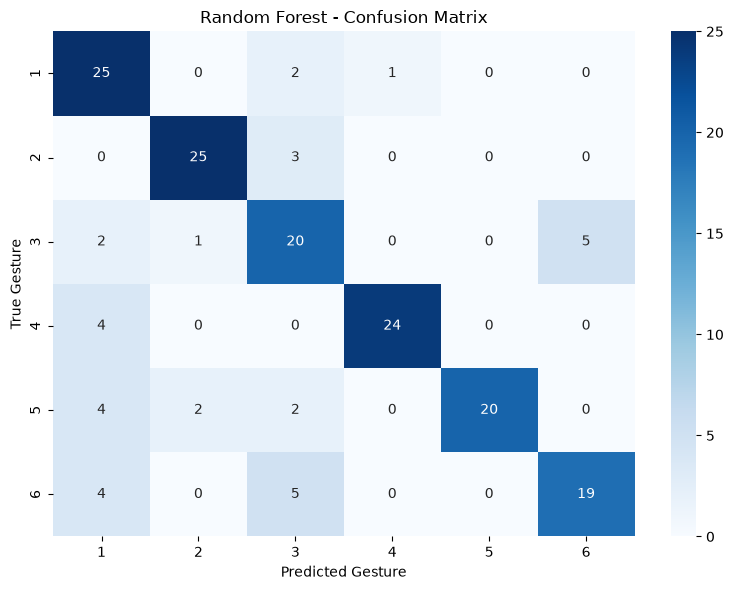


Feature Importance:


,Importance
NE_ch7,0.141995
NE_ch8,0.131859
NE_ch1,0.130130
NE_ch5,0.129933
NE_ch2,0.124804
NE_ch4,0.121298
NE_ch3,0.119822
NE_ch6,0.100159


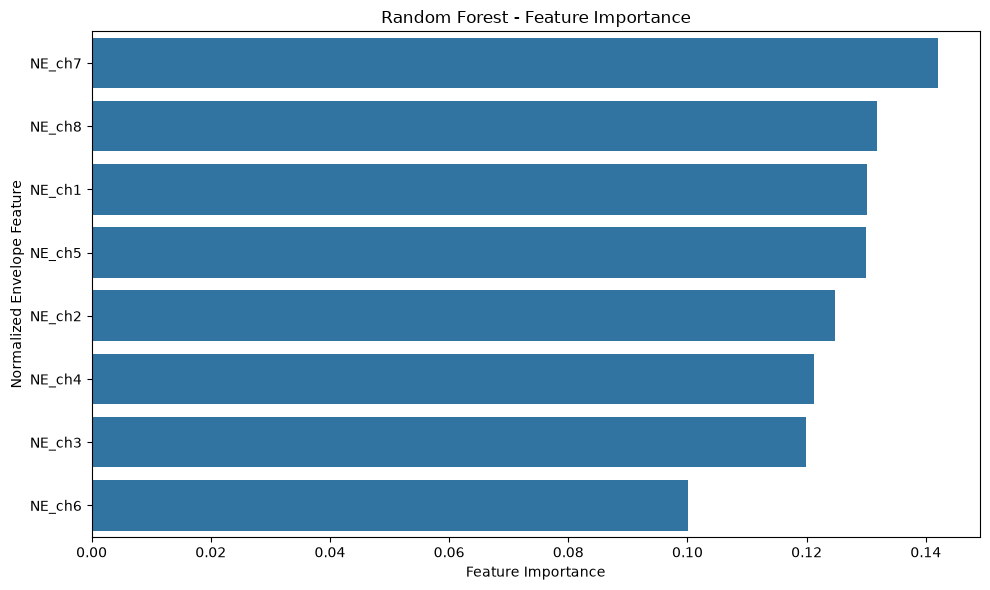

Training accuracy per fold: [0.943 0.948 0.945 0.943 0.955]
Test accuracy per fold: [0.807 0.786 0.893 0.815 0.643]

Mean training accuracy: 0.947
Mean test accuracy: 0.789
Test accuracy SD: 0.081


In [28]:
# ============================================================
# EMG HAND GESTURE CLASSIFICATION - RANDOM FOREST
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import butter, filtfilt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# 2. LOAD DATASET
# ============================================================

data = pd.read_csv("Project_Data_EE4C12_S&S_EMG.csv")

channels = [f"channel{i}" for i in range(1, 9)]

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Total samples: {len(data):,}")
print(f"Total subjects: {data['label'].nunique()}")
print(f"Gesture classes: {sorted(data['class'].unique())}")


# ============================================================
# 3. IDENTIFY RECORDING SESSIONS
# ============================================================

# Identify when time resets for each subject
data["new_series"] = (
    data.groupby("label")["time"]
        .diff()
        .fillna(1)
        <= 0
)

# First row of each subject starts a new series
data["new_series"] = (
    data["new_series"]
    | data.groupby("label").cumcount().eq(0)
)

# Assign series number within each subject
data["series"] = (
    data.groupby("label")["new_series"]
        .cumsum()
        .astype(int)
)

data.drop(columns="new_series", inplace=True)

print("\nTotal recording sessions:",
      data.groupby(["label", "series"]).ngroups)

print("Sessions per subject:")
print(data.groupby("label")["series"].nunique().value_counts())


# ============================================================
# 4. IDENTIFY INDIVIDUAL GESTURE STROKES
# ============================================================

# A new stroke begins when:
# - The gesture class changes
# - The recording session changes
# - The subject changes

data["new_gesture"] = (
    data["class"].ne(data["class"].shift())
    | data["series"].ne(data["series"].shift())
    | data["label"].ne(data["label"].shift())
)

data["gesture_block"] = data["new_gesture"].cumsum()

print("\nTotal gesture blocks:",
      data["gesture_block"].nunique())


# ============================================================
# 5. FEATURE EXTRACTION
# ============================================================

feature_rows = []

# Loop through each gesture stroke
for _, group in data.groupby("gesture_block", sort=False):

    stroke = group[channels].to_numpy(dtype=float)

    # Rectify EMG signal
    rectified = np.abs(stroke)
    fs = 1000
    cutoff = 3
    order = 4

    # Design low-pass Butterworth filter
    b, a = butter(
        order,
        cutoff / (fs / 2),
        btype="low"
    )
    rectified = filtfilt(b, a, rectified, axis=0)

    # Mean Absolute Value
    mav = np.mean(rectified, axis=0)

    # Root Mean Square
    rms = np.sqrt(np.mean(stroke**2, axis=0))

    # Total envelope magnitude
    total_envelope = np.sum(mav)

    # Normalized envelope
    normalized_envelope = mav / (total_envelope + 1e-10)

    # Log total envelope
    log_total_envelope = np.log(total_envelope + 1e-10)

    # Store features
    features = {}

    for ch in range(8):

        features[f"MAV_ch{ch+1}"] = mav[ch]
        features[f"RMS_ch{ch+1}"] = rms[ch]
        features[f"NE_ch{ch+1}"] = normalized_envelope[ch]

    features["Log_Total_Envelope"] = log_total_envelope

    # Store subject, session and gesture class
    features["label"] = group["label"].iloc[0]
    features["series"] = group["series"].iloc[0]
    features["class"] = group["class"].iloc[0]

    feature_rows.append(features)

# Create feature DataFrame
features_df = pd.DataFrame(feature_rows)

# Normalized amplitude (NA):
# Divide each stroke's MAV by the mean MAV of the same channel
# for the same subject and recording session.
# The mean is calculated across all gesture blocks in that session.
mav_cols = [f"MAV_ch{i}" for i in range(1, 9)]
group_cols = ["label", "series", "class"]

# Calculate the mean MAV for each class, person, series, and channel.
class_means = (
    features_df
    .groupby(group_cols)[mav_cols]
    .transform("mean")
)

# Calculate the equally weighted mean across classes
# for each person, series, and channel.
balanced_means = (
    features_df[group_cols + mav_cols]
    .drop_duplicates(subset=group_cols)
    .groupby(["label", "series"])[mav_cols]
    .mean()
)

# Map the balanced reference means back to every gesture.
reference = features_df.set_index(["label", "series"]).index
balanced_values = balanced_means.reindex(reference).to_numpy()

# Calculate normalized amplitude (NA).
for i, col in enumerate(mav_cols):
    features_df[f"NA_ch{i + 1}"] = (
        features_df[col] /
        (balanced_values[:, i] + 1e-10)
    )

print("\n" + "=" * 60)
print("FEATURE EXTRACTION")
print("=" * 60)

print("Feature DataFrame shape:", features_df.shape)
print("Total strokes:", len(features_df))

display(features_df.head())


# ============================================================
# 6. FILTER GESTURE CLASSES
# ============================================================

# Exclude classes 0 and 7
df_model = features_df[
    ~features_df["class"].isin([0, 7])
].copy()

print("\n" + "=" * 60)
print("FILTERED DATASET")
print("=" * 60)

print("Remaining classes:",
      sorted(df_model["class"].unique()))

print("Remaining strokes:", len(df_model))

print("\nStrokes per gesture:")
print(df_model["class"].value_counts().sort_index())


# ============================================================
# 7. SELECT INPUT FEATURES AND TARGET
# ============================================================

# Use 8 normalized envelope features
feature_cols = [f"NE_ch{i}" for i in range(1, 9)]

X = df_model[feature_cols]
y = df_model["class"]

# Group by subject
groups = df_model["label"]

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)
print("Number of subjects:", groups.nunique())

assert groups.nunique() == 36, (
    "Expected 36 subjects. Check the subject labels."
)

assert not X.isna().any().any(), (
    "Missing feature values detected."
)

assert np.isfinite(X.to_numpy()).all(), (
    "Non-finite feature values detected."
)


# ============================================================
# 8. SUBJECT-BASED TRAIN/TEST SPLIT (80/20)
# ============================================================

# 29 subjects for training, 7 for testing
# Both sessions from each subject stay together

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=7,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_subjects = set(groups.iloc[train_idx])
test_subjects = set(groups.iloc[test_idx])

print("\n" + "=" * 60)
print("TRAIN/TEST SPLIT")
print("=" * 60)

print(f"Training subjects: {len(train_subjects)}")
print(f"Testing subjects:  {len(test_subjects)}")

print(f"\nTraining strokes: {len(X_train)}")
print(f"Testing strokes:  {len(X_test)}")

print(f"\nTraining percentage: {len(X_train)/len(X)*100:.2f}%")
print(f"Testing percentage:  {len(X_test)/len(X)*100:.2f}%")

print("\nTraining subject IDs:", sorted(train_subjects))
print("Testing subject IDs:", sorted(test_subjects))

# Verify no subject overlap
assert train_subjects.isdisjoint(test_subjects), (
    "ERROR: Subjects overlap between training and testing!"
)

print("\nSubject overlap: None")

# Verify all gesture classes appear in both sets
expected_classes = set(y.unique())

assert set(y_train.unique()) == expected_classes, (
    "Some gesture classes are missing from training."
)

assert set(y_test.unique()) == expected_classes, (
    "Some gesture classes are missing from testing."
)

# Class distribution
class_distribution = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Testing": y_test.value_counts()
}).fillna(0).astype(int).sort_index()

print("\nClass distribution:")
display(class_distribution)


# ============================================================
# 9. TRAIN REGULARIZED RANDOM FOREST
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("\nRandom Forest training completed.")


# ============================================================
# 10. MODEL PREDICTIONS
# ============================================================

y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)


# ============================================================
# 11. MODEL EVALUATION
# ============================================================

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("\n" + "=" * 60)
print("RANDOM FOREST PERFORMANCE")
print("=" * 60)

print(f"Training accuracy: {train_accuracy:.4f} "
      f"({train_accuracy*100:.2f}%)")

print(f"Testing accuracy:  {test_accuracy:.4f} "
      f"({test_accuracy*100:.2f}%)")

print("\nClassification Report (Test Set):")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

classes = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()


# ============================================================
# 13. FEATURE IMPORTANCE
# ============================================================

importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

print("\nFeature Importance:")
display(importance.to_frame("Importance"))

plt.figure(figsize=(10, 6))

sns.barplot(
    x=importance.values,
    y=importance.index
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Normalized Envelope Feature")

plt.tight_layout()
plt.show()





# ============================================================
# 14. GROUP CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import GroupKFold, cross_validate

cv_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

cv = GroupKFold(n_splits=5)

cv_results = cross_validate(
    cv_model,
    X,
    y,
    groups=groups,
    cv=cv,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=1
)

print("Training accuracy per fold:",
      np.round(cv_results["train_score"], 3))

print("Test accuracy per fold:",
      np.round(cv_results["test_score"], 3))

print(f"\nMean training accuracy: "
      f"{cv_results['train_score'].mean():.3f}")

print(f"Mean test accuracy: "
      f"{cv_results['test_score'].mean():.3f}")

print(f"Test accuracy SD: "
      f"{cv_results['test_score'].std():.3f}")

In [29]:
# ============================================================
# INITIALIZE MODEL COMPARISON
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Store results from each model
model_results = {}

# Keep the original subject-based split
train_indices = X_train.index
test_indices = X_test.index

MODEL 1: NORMALIZED ENVELOPE
Training accuracy: 1.0
Testing accuracy: 0.7916666666666666

Classification Report:
              precision    recall  f1-score   support

           1       0.67      0.93      0.78        28
           2       0.89      0.89      0.89        28
           3       0.65      0.71      0.68        28
           4       0.92      0.86      0.89        28
           5       0.95      0.68      0.79        28
           6       0.79      0.68      0.73        28

    accuracy                           0.79       168
   macro avg       0.81      0.79      0.79       168
weighted avg       0.81      0.79      0.79       168



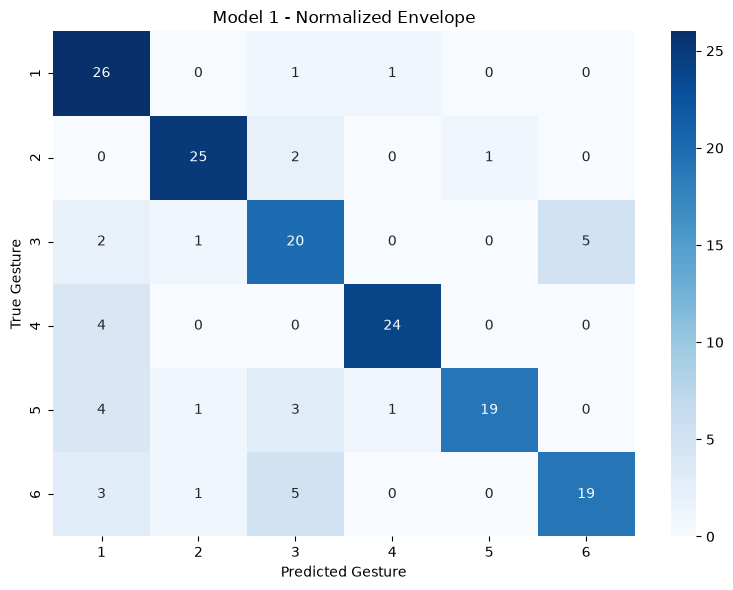

In [30]:
# ============================================================
# MODEL 1: NORMALIZED ENVELOPE
# ============================================================

features_1 = [f"NE_ch{i}" for i in range(1, 9)]

X_train_1 = df_model.loc[train_indices, features_1]
X_test_1 = df_model.loc[test_indices, features_1]

rf_1 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_1.fit(X_train_1, y_train)

y_train_pred_1 = rf_1.predict(X_train_1)
y_test_pred_1 = rf_1.predict(X_test_1)

model_results["NE"] = {
    "n_features": len(features_1),
    "train_accuracy": accuracy_score(y_train, y_train_pred_1),
    "test_accuracy": accuracy_score(y_test, y_test_pred_1),
    "f1_macro": f1_score(y_test, y_test_pred_1, average="macro")
}

print("MODEL 1: NORMALIZED ENVELOPE")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_1))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_1))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_1))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_1),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 1 - Normalized Envelope")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 8: NORMALIZED AMPLITUDE (NA)
Training accuracy: 1.0
Testing accuracy: 0.8988095238095238

Classification Report:
              precision    recall  f1-score   support

           1       0.97      1.00      0.98        28
           2       0.86      0.86      0.86        28
           3       0.72      0.82      0.77        28
           4       1.00      0.96      0.98        28
           5       1.00      0.93      0.96        28
           6       0.88      0.82      0.85        28

    accuracy                           0.90       168
   macro avg       0.90      0.90      0.90       168
weighted avg       0.90      0.90      0.90       168



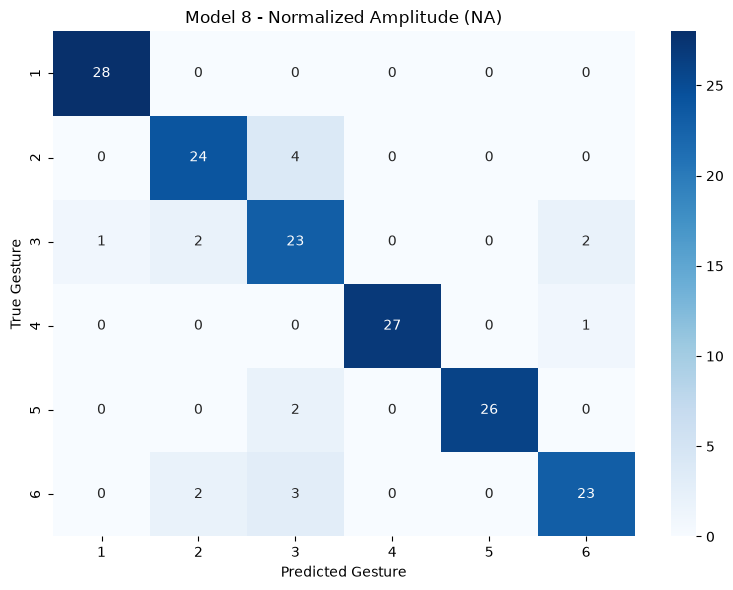

In [31]:
# ============================================================
# MODEL 8: NORMALIZED AMPLITUDE (NA)
# ============================================================

features_NA = [f"NA_ch{i}" for i in range(1, 9)]

X_train_NA = df_model.loc[train_indices, features_NA]
X_test_NA = df_model.loc[test_indices, features_NA]

rf_NA = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_NA.fit(X_train_NA, y_train)

y_train_pred_NA = rf_NA.predict(X_train_NA)
y_test_pred_NA = rf_NA.predict(X_test_NA)

model_results["NA"] = {
    "n_features": len(features_NA),
    "train_accuracy": accuracy_score(y_train, y_train_pred_NA),
    "test_accuracy": accuracy_score(y_test, y_test_pred_NA),
    "f1_macro": f1_score(y_test, y_test_pred_NA, average="macro")
}

print("MODEL 8: NORMALIZED AMPLITUDE (NA)")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_NA))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_NA))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_NA))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_NA),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 8 - Normalized Amplitude (NA)")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 2: MAV
Training accuracy: 1.0
Testing accuracy: 0.8214285714285714

Classification Report:
              precision    recall  f1-score   support

           1       0.90      1.00      0.95        28
           2       0.92      0.82      0.87        28
           3       0.73      0.68      0.70        28
           4       1.00      0.79      0.88        28
           5       0.68      1.00      0.81        28
           6       0.78      0.64      0.71        28

    accuracy                           0.82       168
   macro avg       0.84      0.82      0.82       168
weighted avg       0.84      0.82      0.82       168



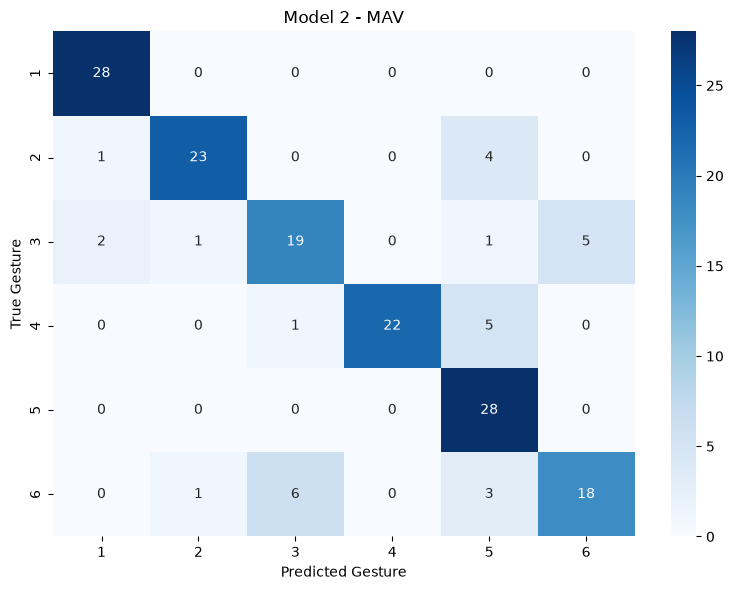

In [32]:
# ============================================================
# MODEL 2: MEAN ABSOLUTE VALUE
# ============================================================

features_2 = [f"MAV_ch{i}" for i in range(1, 9)]

X_train_2 = df_model.loc[train_indices, features_2]
X_test_2 = df_model.loc[test_indices, features_2]

rf_2 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_2.fit(X_train_2, y_train)

y_train_pred_2 = rf_2.predict(X_train_2)
y_test_pred_2 = rf_2.predict(X_test_2)

model_results["MAV"] = {
    "n_features": len(features_2),
    "train_accuracy": accuracy_score(y_train, y_train_pred_2),
    "test_accuracy": accuracy_score(y_test, y_test_pred_2),
    "f1_macro": f1_score(y_test, y_test_pred_2, average="macro")
}

print("MODEL 2: MAV")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_2))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_2))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_2))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_2),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 2 - MAV")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 3: RMS
Training accuracy: 1.0
Testing accuracy: 0.8214285714285714

Classification Report:
              precision    recall  f1-score   support

           1       0.97      1.00      0.98        28
           2       0.92      0.82      0.87        28
           3       0.71      0.71      0.71        28
           4       1.00      0.79      0.88        28
           5       0.68      0.96      0.79        28
           6       0.75      0.64      0.69        28

    accuracy                           0.82       168
   macro avg       0.84      0.82      0.82       168
weighted avg       0.84      0.82      0.82       168



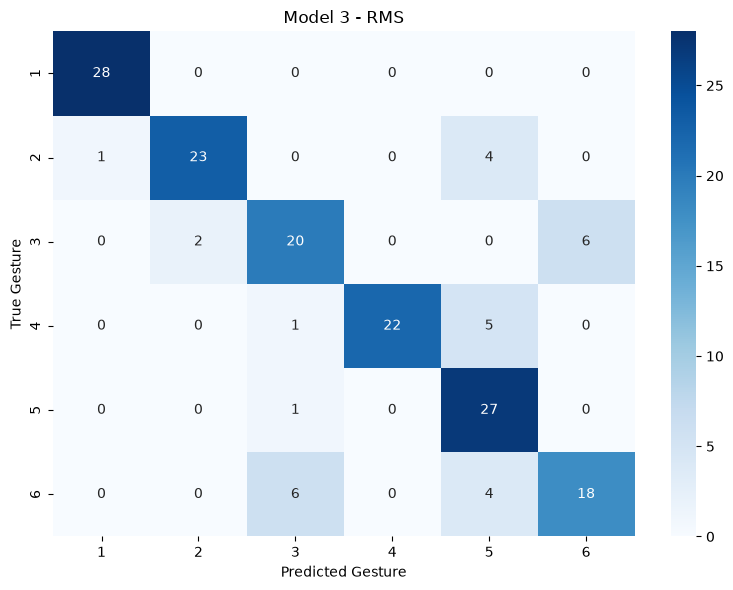

In [33]:
# ============================================================
# MODEL 3: ROOT MEAN SQUARE
# ============================================================

features_3 = [f"RMS_ch{i}" for i in range(1, 9)]

X_train_3 = df_model.loc[train_indices, features_3]
X_test_3 = df_model.loc[test_indices, features_3]

rf_3 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_3.fit(X_train_3, y_train)

y_train_pred_3 = rf_3.predict(X_train_3)
y_test_pred_3 = rf_3.predict(X_test_3)

model_results["RMS"] = {
    "n_features": len(features_3),
    "train_accuracy": accuracy_score(y_train, y_train_pred_3),
    "test_accuracy": accuracy_score(y_test, y_test_pred_3),
    "f1_macro": f1_score(y_test, y_test_pred_3, average="macro")
}

print("MODEL 3: RMS")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_3))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_3))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_3))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_3),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 3 - RMS")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 4: NE + LOG TOTAL ENVELOPE
Training accuracy: 1.0
Testing accuracy: 0.8273809523809523

Classification Report:
              precision    recall  f1-score   support

           1       0.93      1.00      0.97        28
           2       0.82      0.82      0.82        28
           3       0.63      0.68      0.66        28
           4       1.00      0.86      0.92        28
           5       0.81      0.89      0.85        28
           6       0.80      0.71      0.75        28

    accuracy                           0.83       168
   macro avg       0.83      0.83      0.83       168
weighted avg       0.83      0.83      0.83       168



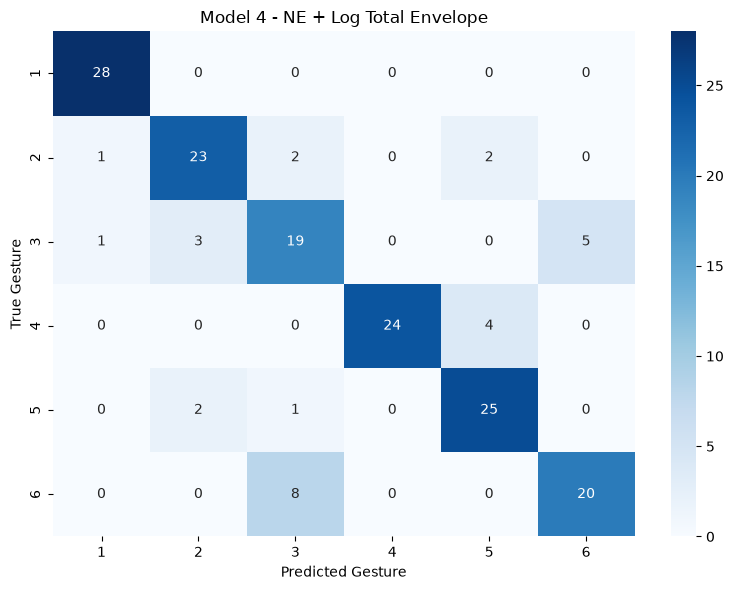

In [34]:
# ============================================================
# MODEL 4: NORMALIZED ENVELOPE + LOG TOTAL ENVELOPE
# ============================================================

features_4 = (
    [f"NE_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
)

X_train_4 = df_model.loc[train_indices, features_4]
X_test_4 = df_model.loc[test_indices, features_4]

rf_4 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_4.fit(X_train_4, y_train)

y_train_pred_4 = rf_4.predict(X_train_4)
y_test_pred_4 = rf_4.predict(X_test_4)

model_results["NE + Log"] = {
    "n_features": len(features_4),
    "train_accuracy": accuracy_score(y_train, y_train_pred_4),
    "test_accuracy": accuracy_score(y_test, y_test_pred_4),
    "f1_macro": f1_score(y_test, y_test_pred_4, average="macro")
}

print("MODEL 4: NE + LOG TOTAL ENVELOPE")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_4))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_4))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_4),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 4 - NE + Log Total Envelope")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 5: MAV + RMS
Training accuracy: 1.0
Testing accuracy: 0.7916666666666666

Classification Report:
              precision    recall  f1-score   support

           1       0.90      1.00      0.95        28
           2       0.69      0.86      0.76        28
           3       0.75      0.64      0.69        28
           4       1.00      0.79      0.88        28
           5       0.71      0.79      0.75        28
           6       0.76      0.68      0.72        28

    accuracy                           0.79       168
   macro avg       0.80      0.79      0.79       168
weighted avg       0.80      0.79      0.79       168



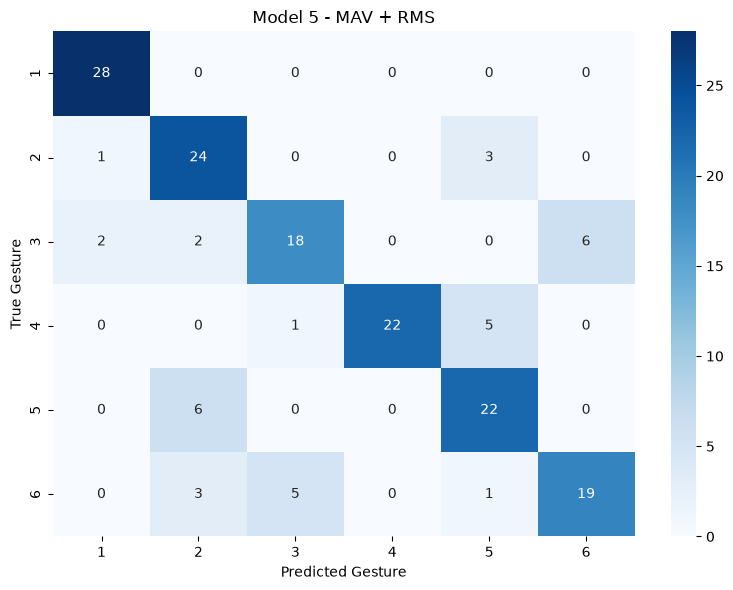

In [35]:
# ============================================================
# MODEL 5: MAV + RMS
# ============================================================

features_5 = (
    [f"MAV_ch{i}" for i in range(1, 9)]
    + [f"RMS_ch{i}" for i in range(1, 9)]
)

X_train_5 = df_model.loc[train_indices, features_5]
X_test_5 = df_model.loc[test_indices, features_5]

rf_5 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_5.fit(X_train_5, y_train)

y_train_pred_5 = rf_5.predict(X_train_5)
y_test_pred_5 = rf_5.predict(X_test_5)

model_results["MAV + RMS"] = {
    "n_features": len(features_5),
    "train_accuracy": accuracy_score(y_train, y_train_pred_5),
    "test_accuracy": accuracy_score(y_test, y_test_pred_5),
    "f1_macro": f1_score(y_test, y_test_pred_5, average="macro")
}

print("MODEL 5: MAV + RMS")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_5))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_5))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_5))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_5),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 5 - MAV + RMS")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 6: ALL FEATURES
Training accuracy: 1.0
Testing accuracy: 0.8690476190476191

Classification Report:
              precision    recall  f1-score   support

           1       0.97      1.00      0.98        28
           2       0.82      0.82      0.82        28
           3       0.82      0.82      0.82        28
           4       1.00      0.86      0.92        28
           5       0.79      0.96      0.87        28
           6       0.84      0.75      0.79        28

    accuracy                           0.87       168
   macro avg       0.87      0.87      0.87       168
weighted avg       0.87      0.87      0.87       168



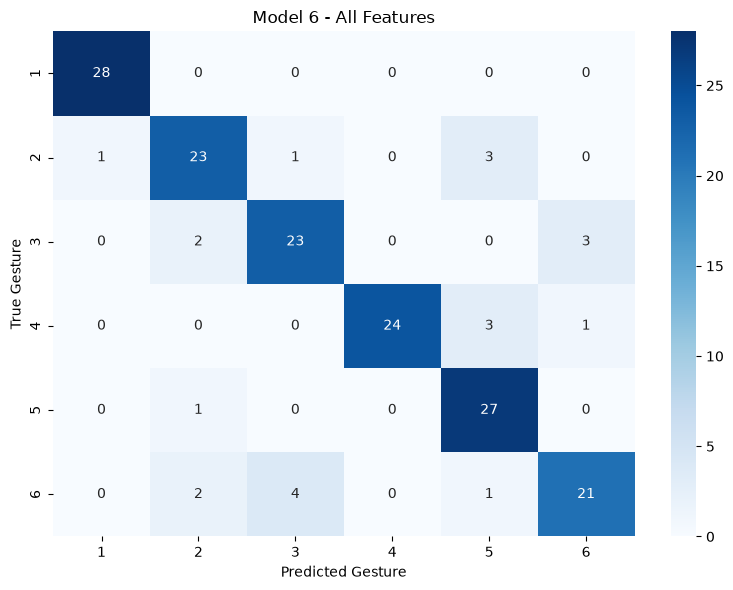

In [36]:
# ============================================================
# MODEL 6: ALL FEATURES
# ============================================================

features_6 = (
    [f"MAV_ch{i}" for i in range(1, 9)]
    + [f"RMS_ch{i}" for i in range(1, 9)]
    + [f"NE_ch{i}" for i in range(1, 9)]
    + [f"NA_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
)

X_train_6 = df_model.loc[train_indices, features_6]
X_test_6 = df_model.loc[test_indices, features_6]

rf_6 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_6.fit(X_train_6, y_train)

y_train_pred_6 = rf_6.predict(X_train_6)
y_test_pred_6 = rf_6.predict(X_test_6)

model_results["All Features"] = {
    "n_features": len(features_6),
    "train_accuracy": accuracy_score(y_train, y_train_pred_6),
    "test_accuracy": accuracy_score(y_test, y_test_pred_6),
    "f1_macro": f1_score(y_test, y_test_pred_6, average="macro")
}

print("MODEL 6: ALL FEATURES")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_6))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_6))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_6))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_6),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 6 - All Features")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 7: NE + LOG TOTAL ENVELOPE + RMS
Training accuracy: 100.00%
Testing accuracy:  83.93%

Classification Report:
              precision    recall  f1-score   support

           1       0.97      1.00      0.98        28
           2       0.85      0.82      0.84        28
           3       0.84      0.75      0.79        28
           4       1.00      0.82      0.90        28
           5       0.67      0.93      0.78        28
           6       0.80      0.71      0.75        28

    accuracy                           0.84       168
   macro avg       0.85      0.84      0.84       168
weighted avg       0.85      0.84      0.84       168



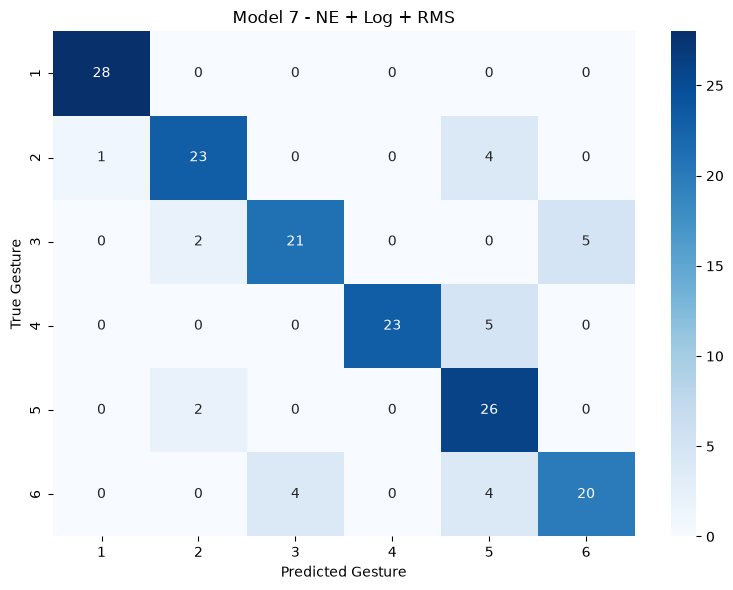

In [37]:
# ============================================================
# MODEL 7: NORMALIZED ENVELOPE + LOG TOTAL ENVELOPE + RMS
# ============================================================

features_7 = (
    [f"NE_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
    + [f"RMS_ch{i}" for i in range(1, 9)]
)

X_train_7 = df_model.loc[train_indices, features_7]
X_test_7 = df_model.loc[test_indices, features_7]

rf_7 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_7.fit(X_train_7, y_train)

y_train_pred_7 = rf_7.predict(X_train_7)
y_test_pred_7 = rf_7.predict(X_test_7)

model_results["NE + Log + RMS"] = {
    "n_features": len(features_7),
    "train_accuracy": accuracy_score(y_train, y_train_pred_7),
    "test_accuracy": accuracy_score(y_test, y_test_pred_7),
    "f1_macro": f1_score(y_test, y_test_pred_7, average="macro")
}

print("=" * 60)
print("MODEL 7: NE + LOG TOTAL ENVELOPE + RMS")
print("=" * 60)

print(f"Training accuracy: {accuracy_score(y_train, y_train_pred_7)*100:.2f}%")
print(f"Testing accuracy:  {accuracy_score(y_test, y_test_pred_7)*100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_7))

# Confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_7),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 7 - NE + Log + RMS")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

RANDOM FOREST MODEL COMPARISON


,n_features,train_accuracy,test_accuracy,f1_macro
NA,8.0,100.0,89.88,90.05
All Features,33.0,100.0,86.90,86.86
NE + Log + RMS,17.0,100.0,83.93,84.07
NE + Log,9.0,100.0,82.74,82.79
MAV,8.0,100.0,82.14,81.97
RMS,8.0,100.0,82.14,82.18
NE,8.0,100.0,79.17,79.30
MAV + RMS,16.0,100.0,79.17,79.10


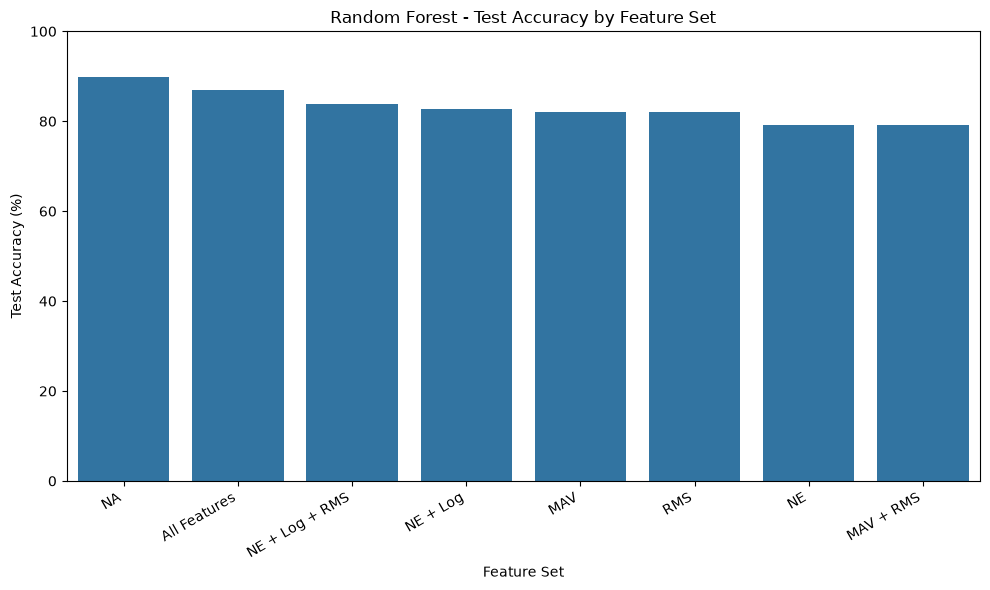

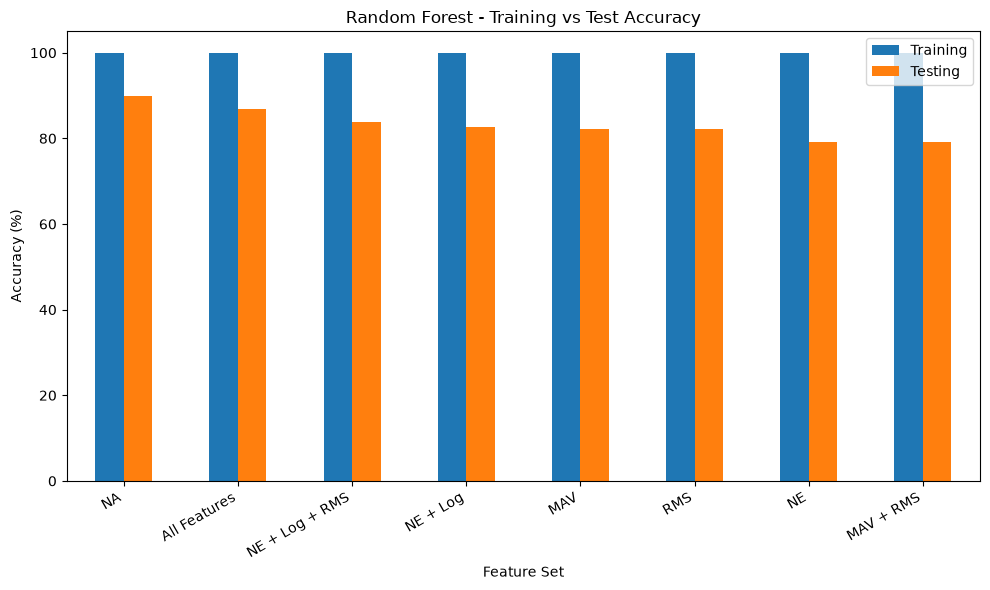

In [38]:
# ============================================================
# RANDOM FOREST MODEL COMPARISON
# ============================================================

# Convert results dictionary into DataFrame
results_df = pd.DataFrame(model_results).T

# Convert accuracy and F1-score to percentages
results_df["train_accuracy"] *= 100
results_df["test_accuracy"] *= 100
results_df["f1_macro"] *= 100

# Sort models by test accuracy
results_df = results_df.sort_values(
    "test_accuracy",
    ascending=False
)

print("=" * 60)
print("RANDOM FOREST MODEL COMPARISON")
print("=" * 60)

display(results_df.round(2))


# ============================================================
# PLOT 1: TEST ACCURACY COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    x=results_df.index,
    y=results_df["test_accuracy"]
)

plt.title("Random Forest - Test Accuracy by Feature Set")
plt.xlabel("Feature Set")
plt.ylabel("Test Accuracy (%)")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 2: TRAINING VS TEST ACCURACY
# ============================================================

accuracy_comparison = results_df[
    ["train_accuracy", "test_accuracy"]
]

accuracy_comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Random Forest - Training vs Test Accuracy")
plt.xlabel("Feature Set")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 105)
plt.legend(["Training", "Testing"])

plt.tight_layout()
plt.show()


MODEL: NE
Fold 1: Accuracy = 75.00% | F1 = 74.45%
Fold 2: Accuracy = 86.11% | F1 = 86.11%
Fold 3: Accuracy = 70.83% | F1 = 71.29%
Fold 4: Accuracy = 74.31% | F1 = 74.16%
Fold 5: Accuracy = 88.33% | F1 = 87.94%

MODEL: NA
Fold 1: Accuracy = 93.75% | F1 = 93.63%
Fold 2: Accuracy = 92.36% | F1 = 92.23%
Fold 3: Accuracy = 79.17% | F1 = 78.98%
Fold 4: Accuracy = 83.33% | F1 = 83.06%
Fold 5: Accuracy = 95.83% | F1 = 95.87%

MODEL: MAV
Fold 1: Accuracy = 81.94% | F1 = 81.98%
Fold 2: Accuracy = 84.03% | F1 = 83.65%
Fold 3: Accuracy = 76.39% | F1 = 76.22%
Fold 4: Accuracy = 81.94% | F1 = 82.14%
Fold 5: Accuracy = 96.67% | F1 = 96.65%

MODEL: RMS
Fold 1: Accuracy = 77.78% | F1 = 77.88%
Fold 2: Accuracy = 83.33% | F1 = 82.83%
Fold 3: Accuracy = 79.86% | F1 = 79.64%
Fold 4: Accuracy = 81.25% | F1 = 81.23%
Fold 5: Accuracy = 94.17% | F1 = 94.10%

MODEL: NE + Log
Fold 1: Accuracy = 76.39% | F1 = 76.02%
Fold 2: Accuracy = 93.06% | F1 = 93.04%
Fold 3: Accuracy = 79.17% | F1 = 79.29%
Fold 4: Accuracy 

,Model,Features,Mean Accuracy (%),Std Accuracy (%),Mean F1 (%)
1,NA,8,88.89,6.47,88.76
7,All Features,33,88.72,6.08,88.65
6,NE + Log + RMS,17,85.22,6.69,85.12
4,NE + Log,9,84.89,6.81,84.82
2,MAV,8,84.19,6.73,84.13
5,MAV + RMS,16,83.75,7.01,83.67
3,RMS,8,83.28,5.74,83.14
0,NE,8,78.92,6.96,78.79


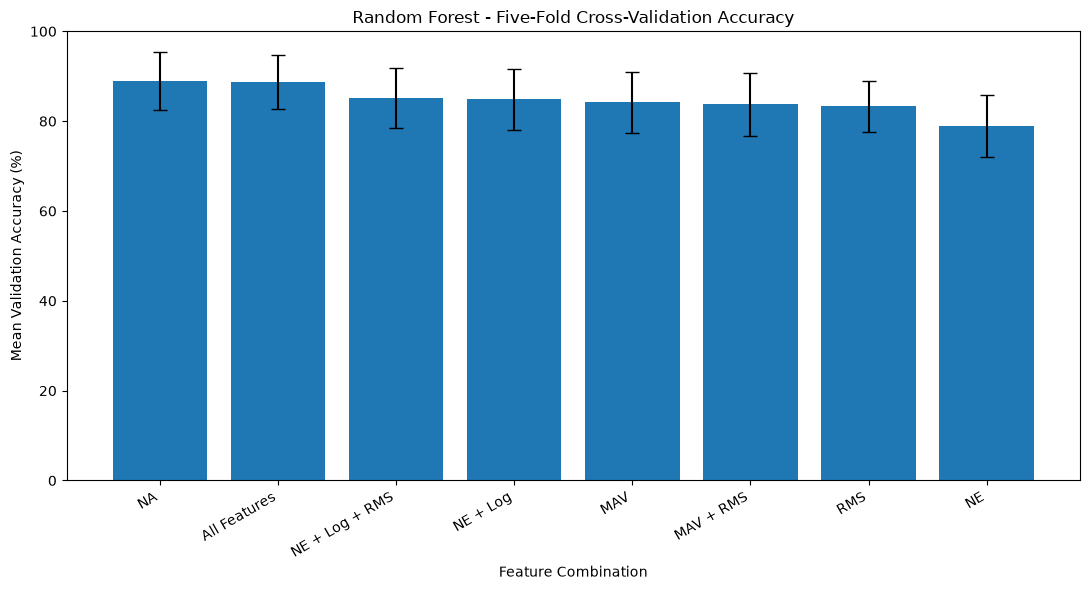

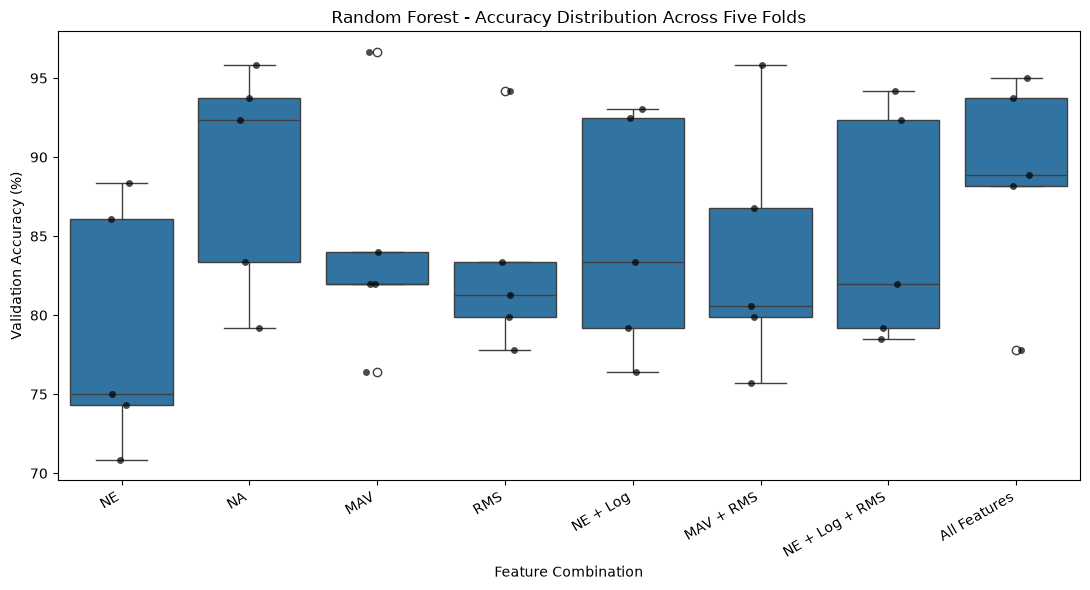

In [39]:
# ============================================================
# FIVE-FOLD GROUP CROSS-VALIDATION
# RANDOM FOREST - ALL FEATURE COMBINATIONS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score


# ============================================================
# 1. DEFINE FEATURE COMBINATIONS
# ============================================================

feature_sets = {
    "NE": [
        f"NE_ch{i}" for i in range(1, 9)
    ],

    "NA": [
        f"NA_ch{i}" for i in range(1, 9)
    ],

    "MAV": [
        f"MAV_ch{i}" for i in range(1, 9)
    ],

    "RMS": [
        f"RMS_ch{i}" for i in range(1, 9)
    ],

    "NE + Log": (
        [f"NE_ch{i}" for i in range(1, 9)]
        + ["Log_Total_Envelope"]
    ),

    "MAV + RMS": (
        [f"MAV_ch{i}" for i in range(1, 9)]
        + [f"RMS_ch{i}" for i in range(1, 9)]
    ),

    "NE + Log + RMS": (
        [f"NE_ch{i}" for i in range(1, 9)]
        + ["Log_Total_Envelope"]
        + [f"RMS_ch{i}" for i in range(1, 9)]
    ),

    "All Features": (
        [f"MAV_ch{i}" for i in range(1, 9)]
        + [f"RMS_ch{i}" for i in range(1, 9)]
        + [f"NE_ch{i}" for i in range(1, 9)]
        + [f"NA_ch{i}" for i in range(1, 9)]
        + ["Log_Total_Envelope"]
    )
}


# ============================================================
# 2. PREPARE TRAINING DATA
# ============================================================

# Only use the original 29 training subjects
cv_df = df_model.loc[train_indices].copy()

y_cv = cv_df["class"]
groups_cv = cv_df["label"]

# Initialize five-fold grouped cross-validation
gkf = GroupKFold(n_splits=5)

# Store results
cv_results = []
fold_results = []


# ============================================================
# 3. RUN CROSS-VALIDATION
# ============================================================

for model_name, feature_cols in feature_sets.items():

    print("\n" + "=" * 60)
    print(f"MODEL: {model_name}")
    print("=" * 60)

    X_cv = cv_df[feature_cols]

    fold_accuracies = []
    fold_f1_scores = []

    for fold, (train_idx, val_idx) in enumerate(
        gkf.split(X_cv, y_cv, groups=groups_cv),
        start=1
    ):

        # Split data
        X_train_fold = X_cv.iloc[train_idx]
        X_val_fold = X_cv.iloc[val_idx]

        y_train_fold = y_cv.iloc[train_idx]
        y_val_fold = y_cv.iloc[val_idx]

        # Verify no subject overlap
        train_groups = set(groups_cv.iloc[train_idx])
        val_groups = set(groups_cv.iloc[val_idx])

        assert train_groups.isdisjoint(val_groups)

        # Create model
        rf = RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )

        # Train model
        rf.fit(X_train_fold, y_train_fold)

        # Predict validation set
        y_pred_fold = rf.predict(X_val_fold)

        # Calculate metrics
        accuracy = accuracy_score(
            y_val_fold, y_pred_fold
        )

        f1 = f1_score(
            y_val_fold,
            y_pred_fold,
            average="macro"
        )

        fold_accuracies.append(accuracy)
        fold_f1_scores.append(f1)

        fold_results.append({
            "Model": model_name,
            "Fold": fold,
            "Accuracy": accuracy * 100,
            "F1 Macro": f1 * 100
        })

        print(
            f"Fold {fold}: "
            f"Accuracy = {accuracy*100:.2f}% | "
            f"F1 = {f1*100:.2f}%"
        )

    # Store summary
    cv_results.append({
        "Model": model_name,
        "Features": len(feature_cols),
        "Mean Accuracy (%)": np.mean(fold_accuracies) * 100,
        "Std Accuracy (%)": np.std(fold_accuracies) * 100,
        "Mean F1 (%)": np.mean(fold_f1_scores) * 100
    })


# ============================================================
# 4. CREATE RESULTS DATAFRAMES
# ============================================================

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    "Mean Accuracy (%)",
    ascending=False
)

fold_results_df = pd.DataFrame(fold_results)

print("\n" + "=" * 60)
print("CROSS-VALIDATION MODEL COMPARISON")
print("=" * 60)

display(cv_results_df.round(2))


# ============================================================
# 5. PLOT MEAN CROSS-VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    cv_results_df["Model"],
    cv_results_df["Mean Accuracy (%)"],
    yerr=cv_results_df["Std Accuracy (%)"],
    capsize=5
)

plt.title("Random Forest - Five-Fold Cross-Validation Accuracy")
plt.xlabel("Feature Combination")
plt.ylabel("Mean Validation Accuracy (%)")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


# ============================================================
# 6. PLOT ACCURACY DISTRIBUTION ACROSS FOLDS
# ============================================================

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=fold_results_df,
    x="Model",
    y="Accuracy"
)

sns.stripplot(
    data=fold_results_df,
    x="Model",
    y="Accuracy",
    color="black",
    alpha=0.7
)

plt.title("Random Forest - Accuracy Distribution Across Five Folds")
plt.xlabel("Feature Combination")
plt.ylabel("Validation Accuracy (%)")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

SVM training completed.

SVM PERFORMANCE
Training accuracy: 88.65%
Testing accuracy:  76.79%
Macro F1-score:    0.7737

Classification Report:
              precision    recall  f1-score   support

           1       0.56      0.86      0.68        28
           2       0.85      0.82      0.84        28
           3       0.70      0.68      0.69        28
           4       0.96      0.86      0.91        28
           5       0.95      0.71      0.82        28
           6       0.76      0.68      0.72        28

    accuracy                           0.77       168
   macro avg       0.80      0.77      0.77       168
weighted avg       0.80      0.77      0.77       168



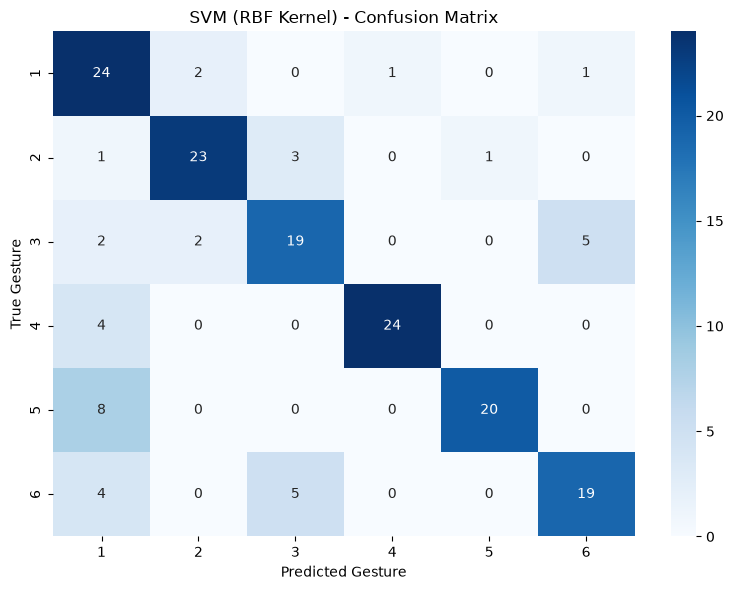

In [40]:
# ============================================================
# SVM MODEL: NORMALIZED ENVELOPE
# ============================================================

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. SELECT FEATURES
# ============================================================

feature_cols = [f"NE_ch{i}" for i in range(1, 9)]

X_train_svm = df_model.loc[X_train.index, feature_cols]
X_test_svm = df_model.loc[X_test.index, feature_cols]


# ============================================================
# 2. CREATE SVM PIPELINE
# ============================================================

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    ))
])


# ============================================================
# 3. TRAIN MODEL
# ============================================================

svm_model.fit(X_train_svm, y_train)

print("SVM training completed.")


# ============================================================
# 4. MAKE PREDICTIONS
# ============================================================

y_train_pred_svm = svm_model.predict(X_train_svm)
y_test_pred_svm = svm_model.predict(X_test_svm)


# ============================================================
# 5. EVALUATE MODEL
# ============================================================

train_accuracy_svm = accuracy_score(
    y_train, y_train_pred_svm
)

test_accuracy_svm = accuracy_score(
    y_test, y_test_pred_svm
)

f1_macro_svm = f1_score(
    y_test, y_test_pred_svm, average="macro"
)

print("\n" + "=" * 60)
print("SVM PERFORMANCE")
print("=" * 60)

print(f"Training accuracy: {train_accuracy_svm*100:.2f}%")
print(f"Testing accuracy:  {test_accuracy_svm*100:.2f}%")
print(f"Macro F1-score:    {f1_macro_svm:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_svm))


# ============================================================
# 6. CONFUSION MATRIX
# ============================================================

classes = sorted(y.unique())

cm_svm = confusion_matrix(
    y_test,
    y_test_pred_svm,
    labels=classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("SVM (RBF Kernel) - Confusion Matrix")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

SVM - NE + LOG + RMS
Training accuracy: 94.83%
Testing accuracy: 79.17%
Macro F1-score: 0.7959

Classification Report:
              precision    recall  f1-score   support

           1       0.87      0.96      0.92        28
           2       0.80      0.71      0.75        28
           3       0.54      0.71      0.62        28
           4       1.00      0.86      0.92        28
           5       0.85      0.82      0.84        28
           6       0.79      0.68      0.73        28

    accuracy                           0.79       168
   macro avg       0.81      0.79      0.80       168
weighted avg       0.81      0.79      0.80       168



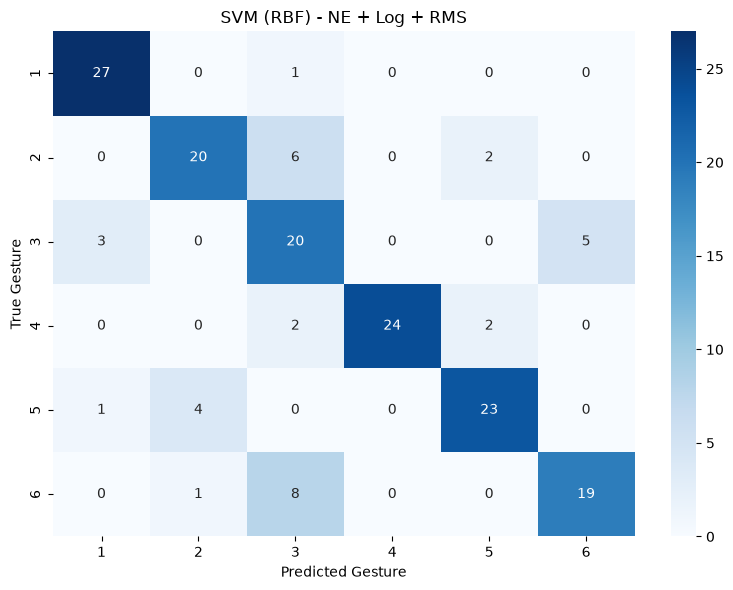

In [41]:
# ============================================================
# SVM: NORMALIZED ENVELOPE + LOG TOTAL ENVELOPE + RMS
# ============================================================

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. SELECT FEATURES
# ============================================================

features_svm_17 = (
    [f"NE_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
    + [f"RMS_ch{i}" for i in range(1, 9)]
)

X_train_svm_17 = df_model.loc[
    train_indices, features_svm_17
]

X_test_svm_17 = df_model.loc[
    test_indices, features_svm_17
]


# ============================================================
# 2. CREATE AND TRAIN SVM
# ============================================================

svm_17 = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

svm_17.fit(X_train_svm_17, y_train)


# ============================================================
# 3. PREDICTIONS
# ============================================================

y_train_pred = svm_17.predict(X_train_svm_17)
y_test_pred = svm_17.predict(X_test_svm_17)


# ============================================================
# 4. EVALUATION
# ============================================================

print("=" * 60)
print("SVM - NE + LOG + RMS")
print("=" * 60)

print(
    f"Training accuracy: "
    f"{accuracy_score(y_train, y_train_pred)*100:.2f}%"
)

print(
    f"Testing accuracy: "
    f"{accuracy_score(y_test, y_test_pred)*100:.2f}%"
)

print(
    f"Macro F1-score: "
    f"{f1_score(y_test, y_test_pred, average='macro'):.4f}"
)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))


# ============================================================
# 5. CONFUSION MATRIX
# ============================================================

classes = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("SVM (RBF) - NE + Log + RMS")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

In [42]:
# ============================================================
# 9. DEEP LEARNING MODEL - MULTILAYER PERCEPTRON
# ============================================================
"""
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ------------------------------------------------------------
# 9.1 Create a subject-based validation split
# ------------------------------------------------------------

# Use only the training subjects for model development.
train_groups = groups.iloc[train_idx].reset_index(drop=True)

X_train_reset = X_train.reset_index(drop=True)
y_train_reset = y_train.reset_index(drop=True)

# Keep complete subjects together in the validation split.
val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

fit_idx, val_idx = next(
    val_splitter.split(
        X_train_reset,
        y_train_reset,
        groups=train_groups
    )
)

X_fit = X_train_reset.iloc[fit_idx]
X_val = X_train_reset.iloc[val_idx]

y_fit = y_train_reset.iloc[fit_idx]
y_val = y_train_reset.iloc[val_idx]

# Verify that subjects do not overlap.
fit_subjects = set(train_groups.iloc[fit_idx])
val_subjects = set(train_groups.iloc[val_idx])

assert fit_subjects.isdisjoint(val_subjects)

print("Model-training subjects:", len(fit_subjects))
print("Validation subjects:", len(val_subjects))
print("Final test subjects:", len(test_subjects))

# ------------------------------------------------------------
# 9.2 Standardize features
# ------------------------------------------------------------

# Fit the scaler only on the model-training data.
scaler = StandardScaler()

X_fit_scaled = scaler.fit_transform(X_fit)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------
# 9.3 Encode gesture labels
# ------------------------------------------------------------

# Map gesture labels to consecutive integers starting at zero.
label_encoder = LabelEncoder()

y_fit_encoded = label_encoder.fit_transform(y_fit)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

n_classes = len(label_encoder.classes_)
n_features = X_fit_scaled.shape[1]

# ------------------------------------------------------------
# 9.4 Define the neural network
# ------------------------------------------------------------

model = Sequential([
    Input(shape=(n_features,)),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),
    Dropout(0.30),

    Dense(
        16,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),
    Dropout(0.20),

    Dense(n_classes, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ------------------------------------------------------------
# 9.5 Train with early stopping
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_fit_scaled,
    y_fit_encoded,
    validation_data=(X_val_scaled, y_val_encoded),
    epochs=200,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

# ------------------------------------------------------------
# 9.6 Evaluate on the independent test subjects
# ------------------------------------------------------------

train_pred = np.argmax(
    model.predict(X_fit_scaled, verbose=0),
    axis=1
)

test_pred = np.argmax(
    model.predict(X_test_scaled, verbose=0),
    axis=1
)

train_accuracy = accuracy_score(y_fit_encoded, train_pred)
test_accuracy = accuracy_score(y_test_encoded, test_pred)

print(f"\nTraining accuracy: {train_accuracy:.4f}")
print(f"Test accuracy:     {test_accuracy:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test_encoded,
    test_pred,
    labels=np.arange(n_classes),
    target_names=[
        str(c) for c in label_encoder.classes_
    ],
    zero_division=0
))

# ------------------------------------------------------------
# 9.7 Plot learning curves
# ------------------------------------------------------------

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Loss")
plt.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9.8 Plot confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test_encoded,
    test_pred,
    labels=np.arange(n_classes)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("MLP - Test Confusion Matrix")
plt.tight_layout()
plt.show()
"""

'\nimport numpy as np\nimport tensorflow as tf\nimport matplotlib.pyplot as plt\n\nfrom sklearn.model_selection import GroupShuffleSplit\nfrom sklearn.preprocessing import StandardScaler, LabelEncoder\nfrom sklearn.metrics import (\n    accuracy_score,\n    classification_report,\n    confusion_matrix,\n    ConfusionMatrixDisplay\n)\nfrom tensorflow.keras.models import Sequential\nfrom tensorflow.keras.layers import Input, Dense, Dropout\nfrom tensorflow.keras.callbacks import EarlyStopping\nfrom tensorflow.keras.regularizers import l2\n\n# Reproducibility\nnp.random.seed(42)\ntf.random.set_seed(42)\n\n# ------------------------------------------------------------\n# 9.1 Create a subject-based validation split\n# ------------------------------------------------------------\n\n# Use only the training subjects for model development.\ntrain_groups = groups.iloc[train_idx].reset_index(drop=True)\n\nX_train_reset = X_train.reset_index(drop=True)\ny_train_reset = y_train.reset_index(drop=Tru

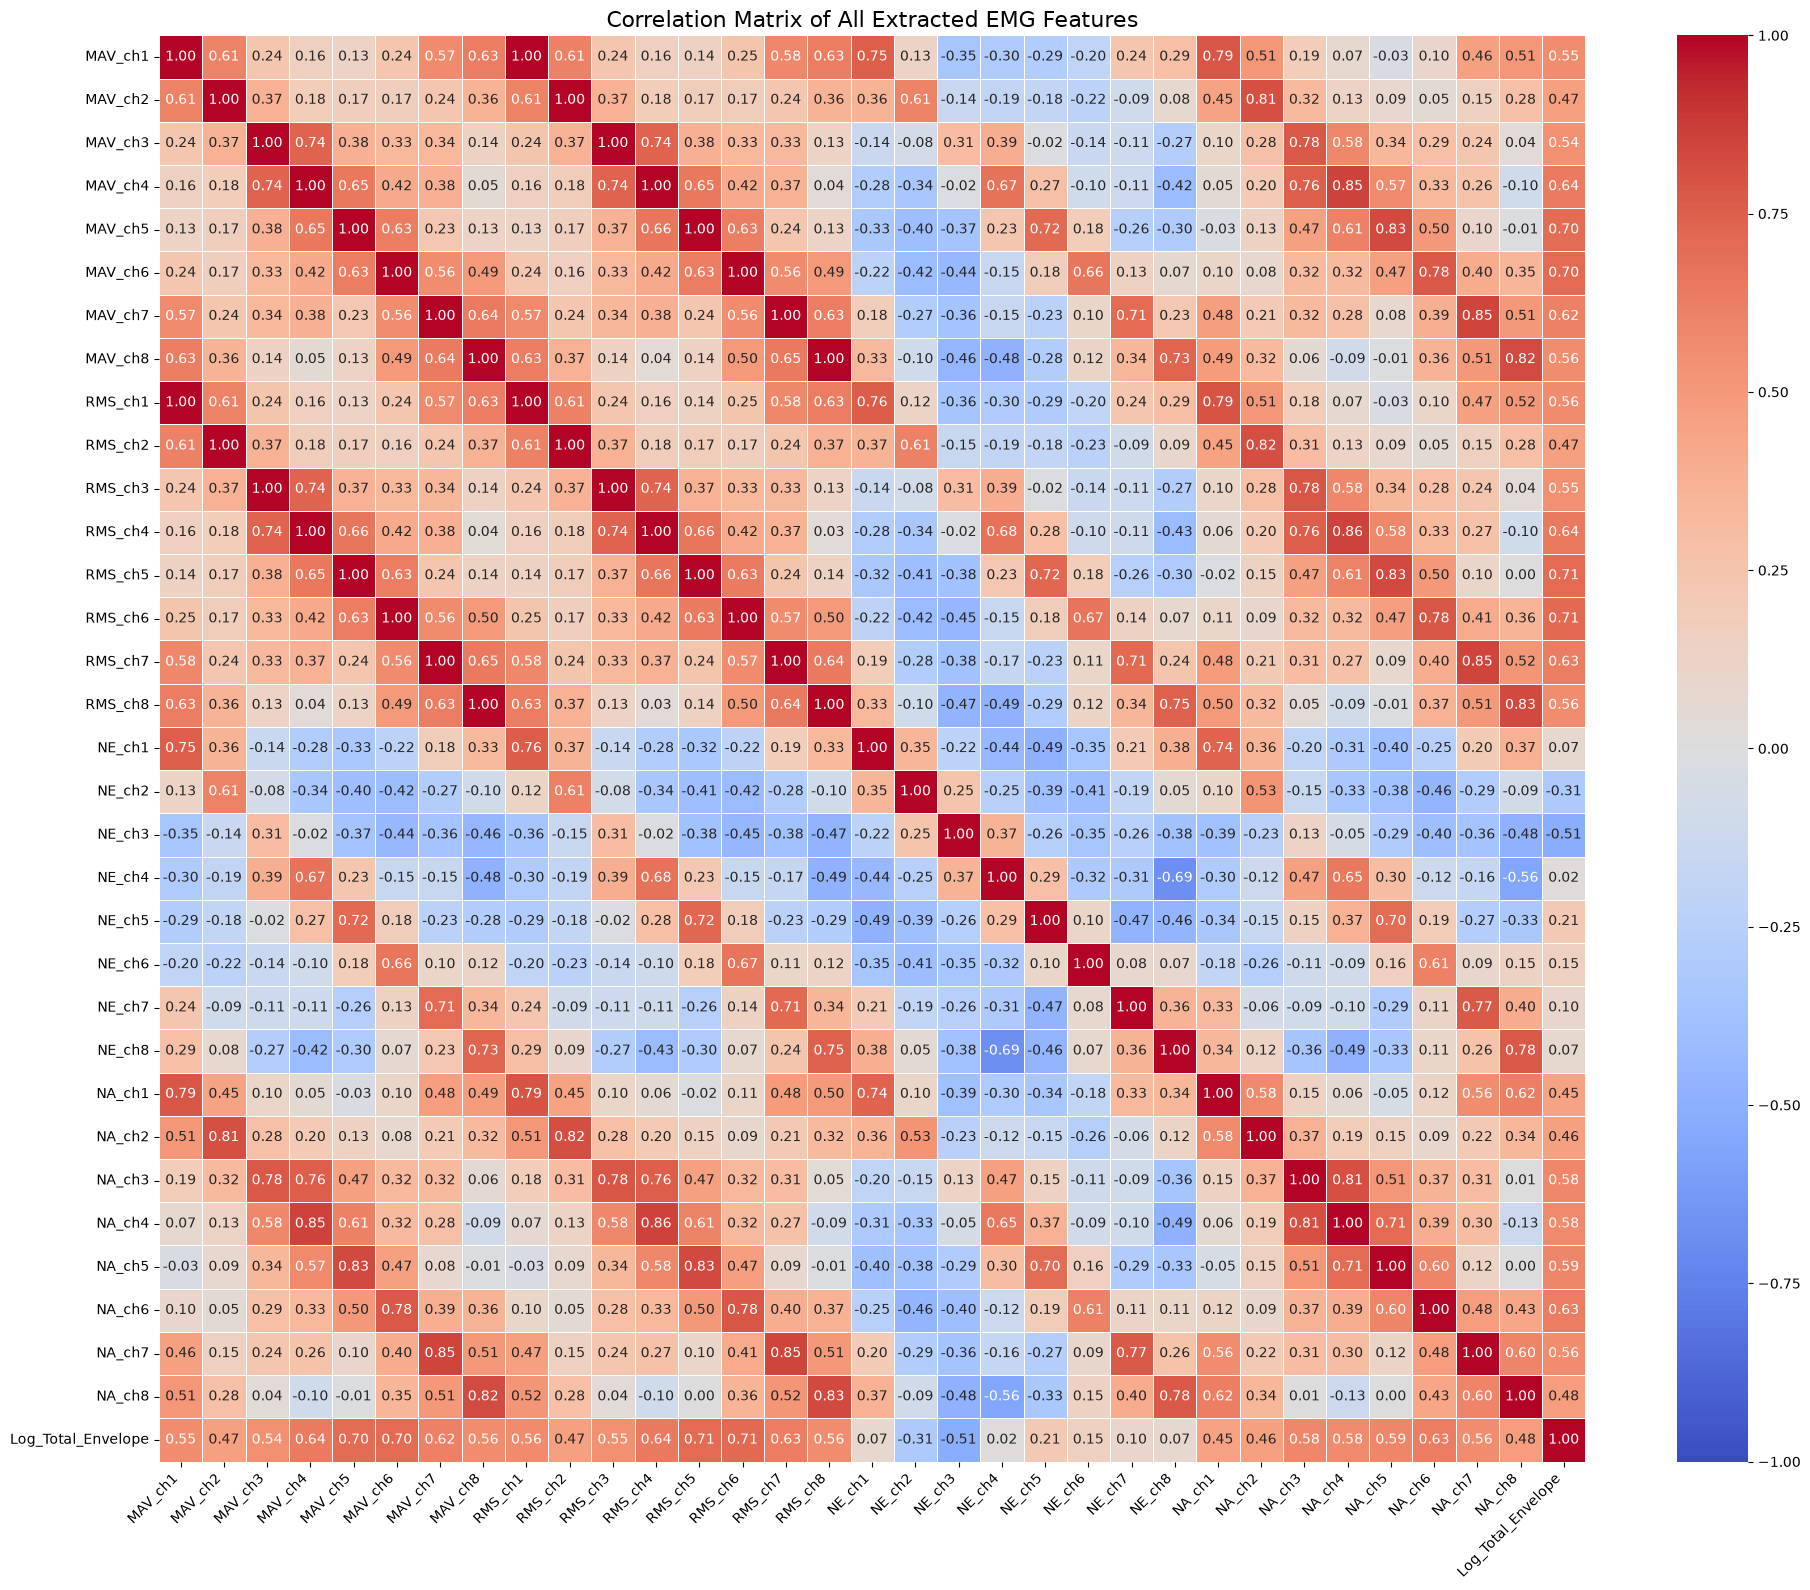

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select all extracted numerical features
feature_cols = (
    [f"MAV_ch{i}" for i in range(1, 9)]
    + [f"RMS_ch{i}" for i in range(1, 9)]
    + [f"NE_ch{i}" for i in range(1, 9)]
    + [f"NA_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
)

# Calculate the Pearson correlation matrix
correlation_matrix = df_model[feature_cols].corr(method="pearson")

# Visualize the correlation matrix
plt.figure(figsize=(20, 16))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Matrix of All Extracted EMG Features", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Vanaf hieronder de resultaten

In [44]:
# ============================================================
# 1. IMPORT LIBRARIES AND PREPARE DATA
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Use the same eight normalized-envelope features as your current model.
feature_cols = [f"NA_ch{i}" for i in range(1, 9)]

df_eval = features_df[
    ~features_df["class"].isin([0, 7])
].copy().reset_index(drop=True)

X = df_eval[feature_cols]
y = df_eval["class"]
groups = df_eval["label"]  # Group by person, not individual gesture

classes = sorted(y.unique())

assert X.notna().all().all(), "Missing feature values detected."
assert np.isfinite(X.to_numpy()).all(), "Non-finite feature values detected."

print("Number of gestures:", len(df_eval))
print("Number of subjects:", groups.nunique())
print("Gesture classes:", classes)
print("\nGestures per class:")
print(y.value_counts().sort_index())

Number of gestures: 864
Number of subjects: 36
Gesture classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

Gestures per class:
class
1    144
2    144
3    144
4    144
5    144
6    144
Name: count, dtype: int64


In [45]:
# ============================================================
# 2. DEFINE MODELS AND HYPERPARAMETER GRIDS
# ============================================================

models = {
    "Linear SVM": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(kernel="linear", class_weight="balanced"))
        ]),
        "params": {
            "model__C": [0.01, 0.1, 1, 10, 100]
        }
    },

    "RBF SVM": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(kernel="rbf", class_weight="balanced"))
        ]),
        "params": {
            "model__C": [0.1, 1, 10, 100],
            "model__gamma": ["scale", 0.01, 0.1, 1]
        }
    },

    "k-NN": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier())
        ]),
        "params": {
            "model__n_neighbors": [3, 5, 7, 11, 15],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]  # Manhattan or Euclidean distance
        }
    },

    "Random Forest": {
        "pipeline": Pipeline([
            ("model", RandomForestClassifier(
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ))
        ]),
        "params": {
            "model__n_estimators": [200, 400],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_leaf": [1, 3, 5],
            "model__max_features": ["sqrt", 0.75]
        }
    },

    "MLP": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("model", MLPClassifier(
                max_iter=1500,
                early_stopping=True,
                random_state=42
            ))
        ]),
        "params": {
            "model__hidden_layer_sizes": [
                (32,),
                (64,),
                (64, 32),
                (128, 64)
            ],
            "model__alpha": [0.0001, 0.01, 0.1],
            "model__learning_rate_init": [0.001, 0.01]
        }
    }
}

In [46]:
# ============================================================
# 3. GENERATE FIVE TRAIN/TEST SPLITS
# ============================================================

N_RUNS = 5
TEST_SIZE = 0.20
BASE_SEED = 42

splitter = GroupShuffleSplit(
    n_splits=N_RUNS,
    test_size=TEST_SIZE,
    random_state=BASE_SEED
)

splits = []

for run, (train_idx, test_idx) in enumerate(
    splitter.split(X, y, groups=groups), start=1
):
    train_subjects = set(groups.iloc[train_idx])
    test_subjects = set(groups.iloc[test_idx])

    # Verify subject independence
    assert train_subjects.isdisjoint(test_subjects)

    # Verify that every class is represented in both sets
    if set(y.iloc[train_idx]) != set(classes):
        raise ValueError(
            f"Run {run}: one or more classes are missing from training. "
            "Try another split configuration."
        )

    if set(y.iloc[test_idx]) != set(classes):
        raise ValueError(
            f"Run {run}: one or more classes are missing from testing. "
            "Try another split configuration."
        )

    splits.append((train_idx, test_idx))

    print(
        f"Run {run}: "
        f"{len(train_subjects)} training subjects, "
        f"{len(test_subjects)} test subjects, "
        f"{len(train_idx)} training gestures, "
        f"{len(test_idx)} test gestures"
    )

Run 1: 28 training subjects, 8 test subjects, 672 training gestures, 192 test gestures
Run 2: 28 training subjects, 8 test subjects, 672 training gestures, 192 test gestures
Run 3: 28 training subjects, 8 test subjects, 672 training gestures, 192 test gestures
Run 4: 28 training subjects, 8 test subjects, 672 training gestures, 192 test gestures
Run 5: 28 training subjects, 8 test subjects, 672 training gestures, 192 test gestures


In [47]:
# ============================================================
# 4. TRAIN AND EVALUATE ALL MODELS OVER FIVE RUNS
# ============================================================

results = []
predictions = {}
best_parameters = {}

for model_name, config in models.items():

    print("\n" + "=" * 75)
    print(f"MODEL: {model_name}")
    print("=" * 75)

    predictions[model_name] = []
    best_parameters[model_name] = []

    for run, (train_idx, test_idx) in enumerate(splits, start=1):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]
        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]
        groups_train = groups.iloc[train_idx]

        # Use group-based CV so the same subject cannot occur
        # in both the CV training and validation folds.
        n_cv_splits = min(5, groups_train.nunique())

        cv = GroupKFold(n_splits=n_cv_splits)

        search = GridSearchCV(
            estimator=clone(config["pipeline"]),
            param_grid=config["params"],
            scoring="accuracy",
            cv=cv,
            n_jobs=-1,
            refit=True,
            error_score="raise"
        )

        search.fit(
            X_train,
            y_train,
            groups=groups_train
        )

        best_model = search.best_estimator_
        y_pred = best_model.predict(X_test)

        run_result = {
            "Model": model_name,
            "Run": run,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Macro Precision": precision_score(
                y_test, y_pred, average="macro", zero_division=0
            ),
            "Macro Recall": recall_score(
                y_test, y_pred, average="macro", zero_division=0
            ),
            "Macro F1": f1_score(
                y_test, y_pred, average="macro", zero_division=0
            ),
            "CV Accuracy": search.best_score_
        }

        results.append(run_result)

        predictions[model_name].append({
            "run": run,
            "y_test": y_test.copy(),
            "y_pred": y_pred.copy(),
            "accuracy": run_result["Accuracy"],
            "best_model": best_model,
            "test_idx": test_idx.copy()
        })

        best_parameters[model_name].append({
            "Run": run,
            "Best Parameters": search.best_params_
        })

        print(
            f"Run {run}: "
            f"test accuracy = {run_result['Accuracy']:.3f}, "
            f"CV accuracy = {search.best_score_:.3f}"
        )
        print("Best parameters:", search.best_params_)

results_df = pd.DataFrame(results)


MODEL: Linear SVM
Run 1: test accuracy = 0.880, CV accuracy = 0.907
Best parameters: {'model__C': 10}
Run 2: test accuracy = 0.896, CV accuracy = 0.903
Best parameters: {'model__C': 1}
Run 3: test accuracy = 0.943, CV accuracy = 0.901
Best parameters: {'model__C': 0.1}
Run 4: test accuracy = 0.953, CV accuracy = 0.876
Best parameters: {'model__C': 0.1}
Run 5: test accuracy = 0.938, CV accuracy = 0.902
Best parameters: {'model__C': 0.1}

MODEL: RBF SVM
Run 1: test accuracy = 0.901, CV accuracy = 0.910
Best parameters: {'model__C': 10, 'model__gamma': 0.1}
Run 2: test accuracy = 0.896, CV accuracy = 0.906
Best parameters: {'model__C': 1, 'model__gamma': 'scale'}
Run 3: test accuracy = 0.943, CV accuracy = 0.903
Best parameters: {'model__C': 10, 'model__gamma': 0.01}
Run 4: test accuracy = 0.964, CV accuracy = 0.870
Best parameters: {'model__C': 10, 'model__gamma': 0.01}
Run 5: test accuracy = 0.938, CV accuracy = 0.895
Best parameters: {'model__C': 10, 'model__gamma': 0.01}

MODEL: k-NN

In [48]:
# ============================================================
# 5. SUMMARY OF PERFORMANCE
# ============================================================

metric_cols = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

summary = (
    results_df
    .groupby("Model")[metric_cols]
    .agg(["mean", "std"])
)

# Flatten the multi-level column names
summary.columns = [
    f"{metric} {stat}".title()
    for metric, stat in summary.columns
]

summary = summary.reset_index()

print("Mean performance and standard deviation across five runs:")
display(summary.round(4))

print("\nIndividual run results:")
display(
    results_df.sort_values(["Model", "Run"]).round(4)
)

Mean performance and standard deviation across five runs:


,Model,Accuracy Mean,Accuracy Std,Macro Precision Mean,Macro Precision Std,Macro Recall Mean,Macro Recall Std,Macro F1 Mean,Macro F1 Std
0,Linear SVM,0.9219,0.0319,0.9259,0.0287,0.9219,0.0319,0.9217,0.0316
1,MLP,0.9052,0.0298,0.9114,0.0293,0.9052,0.0298,0.9055,0.0295
2,RBF SVM,0.9281,0.0289,0.9310,0.0277,0.9281,0.0289,0.9280,0.0287
3,Random Forest,0.9240,0.0303,0.9278,0.0280,0.9240,0.0303,0.9241,0.0302
4,k-NN,0.9146,0.0369,0.9194,0.0348,0.9146,0.0369,0.9144,0.0372



Individual run results:


,Model,Run,Accuracy,Macro Precision,Macro Recall,Macro F1,CV Accuracy
0,Linear SVM,1,0.8802,0.8894,0.8802,0.8811,0.9069
1,Linear SVM,2,0.8958,0.9015,0.8958,0.8950,0.9025
2,Linear SVM,3,0.9427,0.9423,0.9427,0.9422,0.9014
3,Linear SVM,4,0.9531,0.9555,0.9531,0.9533,0.8758
4,Linear SVM,5,0.9375,0.9411,0.9375,0.9367,0.9022
20,MLP,1,0.8698,0.8780,0.8698,0.8710,0.9053
21,MLP,2,0.8802,0.8845,0.8802,0.8800,0.8944
22,MLP,3,0.9167,0.9287,0.9167,0.9183,0.8867
23,MLP,4,0.9427,0.9464,0.9427,0.9425,0.8594
24,MLP,5,0.9167,0.9193,0.9167,0.9158,0.8842



Linear SVM — representative run 5 (accuracy = 0.938; five-run mean = 0.922)


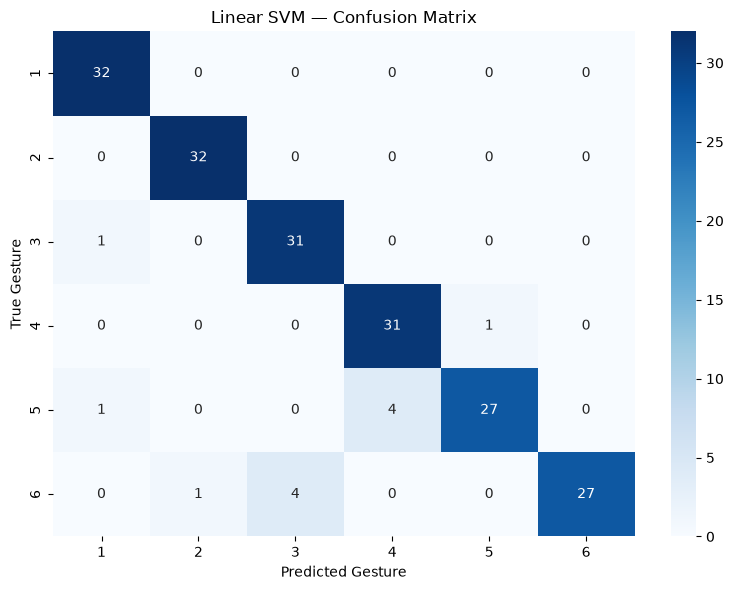


Classification report for representative test split:
              precision    recall  f1-score   support

           1       0.94      1.00      0.97        32
           2       0.97      1.00      0.98        32
           3       0.89      0.97      0.93        32
           4       0.89      0.97      0.93        32
           5       0.96      0.84      0.90        32
           6       1.00      0.84      0.92        32

    accuracy                           0.94       192
   macro avg       0.94      0.94      0.94       192
weighted avg       0.94      0.94      0.94       192


RBF SVM — representative run 5 (accuracy = 0.938; five-run mean = 0.928)


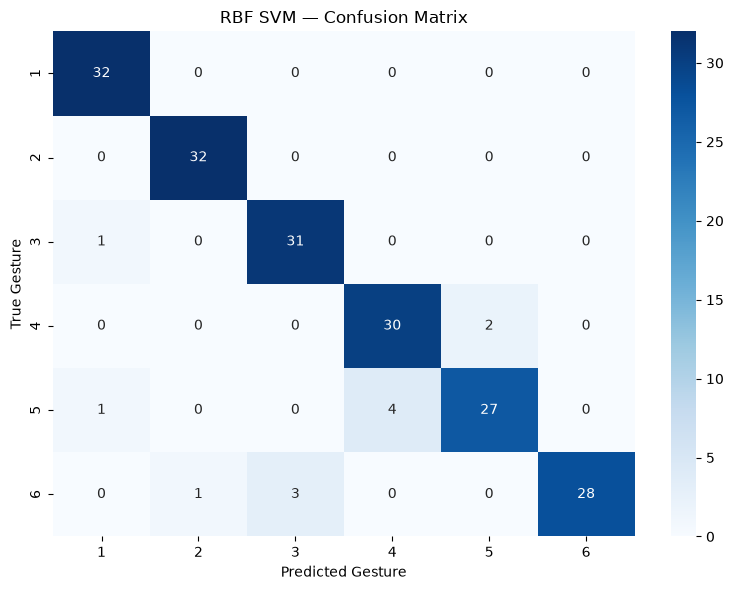


Classification report for representative test split:
              precision    recall  f1-score   support

           1       0.94      1.00      0.97        32
           2       0.97      1.00      0.98        32
           3       0.91      0.97      0.94        32
           4       0.88      0.94      0.91        32
           5       0.93      0.84      0.89        32
           6       1.00      0.88      0.93        32

    accuracy                           0.94       192
   macro avg       0.94      0.94      0.94       192
weighted avg       0.94      0.94      0.94       192


k-NN — representative run 3 (accuracy = 0.927; five-run mean = 0.915)


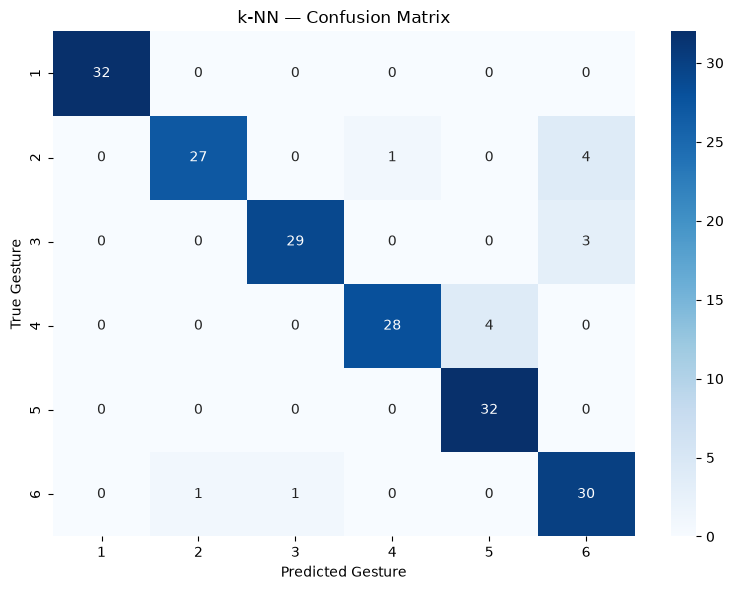


Classification report for representative test split:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        32
           2       0.96      0.84      0.90        32
           3       0.97      0.91      0.94        32
           4       0.97      0.88      0.92        32
           5       0.89      1.00      0.94        32
           6       0.81      0.94      0.87        32

    accuracy                           0.93       192
   macro avg       0.93      0.93      0.93       192
weighted avg       0.93      0.93      0.93       192


Random Forest — representative run 1 (accuracy = 0.917; five-run mean = 0.924)


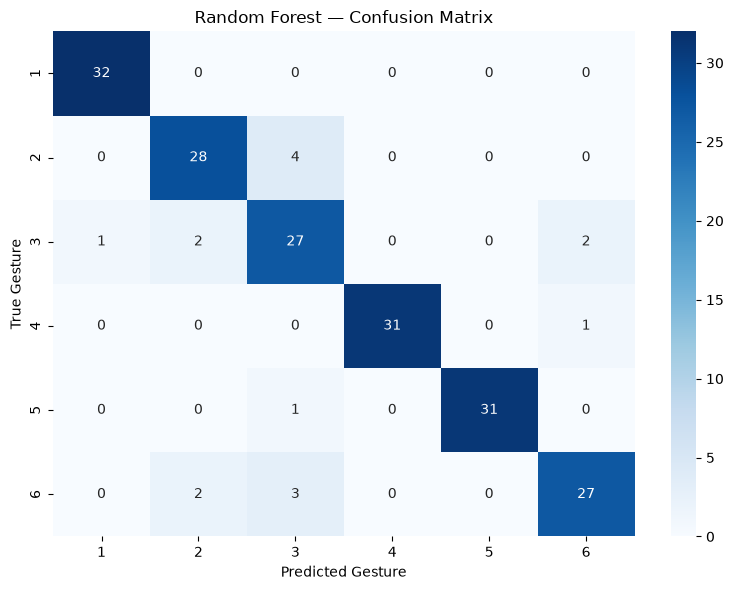


Classification report for representative test split:
              precision    recall  f1-score   support

           1       0.97      1.00      0.98        32
           2       0.88      0.88      0.88        32
           3       0.77      0.84      0.81        32
           4       1.00      0.97      0.98        32
           5       1.00      0.97      0.98        32
           6       0.90      0.84      0.87        32

    accuracy                           0.92       192
   macro avg       0.92      0.92      0.92       192
weighted avg       0.92      0.92      0.92       192


MLP — representative run 3 (accuracy = 0.917; five-run mean = 0.905)


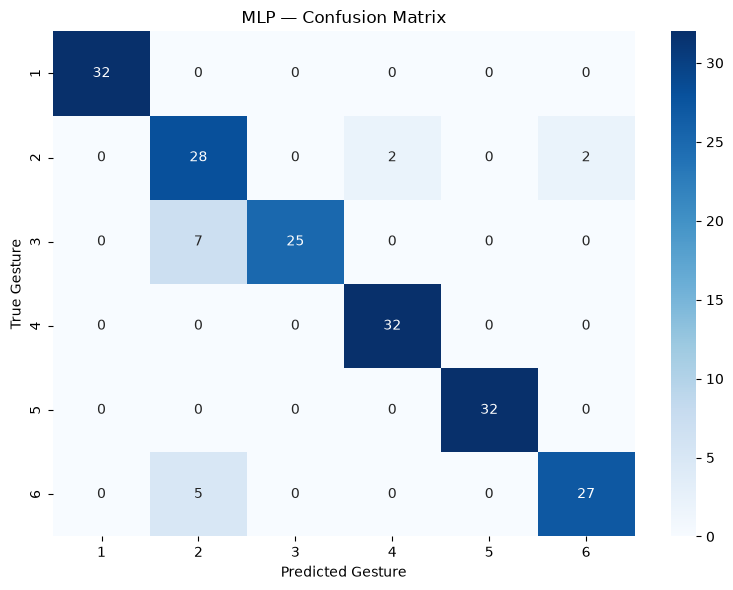


Classification report for representative test split:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        32
           2       0.70      0.88      0.78        32
           3       1.00      0.78      0.88        32
           4       0.94      1.00      0.97        32
           5       1.00      1.00      1.00        32
           6       0.93      0.84      0.89        32

    accuracy                           0.92       192
   macro avg       0.93      0.92      0.92       192
weighted avg       0.93      0.92      0.92       192



In [49]:
# ============================================================
# 6. CONFUSION MATRICES
# ============================================================

for model_name in models:

    run_predictions = predictions[model_name]

    mean_accuracy = np.mean([
        result["accuracy"] for result in run_predictions
    ])

    # Select the run closest to the model's mean accuracy
    representative = min(
        run_predictions,
        key=lambda result: abs(result["accuracy"] - mean_accuracy)
    )

    y_test_rep = representative["y_test"]
    y_pred_rep = representative["y_pred"]

    cm = confusion_matrix(
        y_test_rep,
        y_pred_rep,
        labels=classes
    )

    print(
        f"\n{model_name} — representative run "
        f"{representative['run']} "
        f"(accuracy = {representative['accuracy']:.3f}; "
        f"five-run mean = {mean_accuracy:.3f})"
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes
    )

    plt.title(f"{model_name} — Confusion Matrix")
    plt.xlabel("Predicted Gesture")
    plt.ylabel("True Gesture")
    plt.tight_layout()
    plt.show()

    print("\nClassification report for representative test split:")
    print(classification_report(
        y_test_rep,
        y_pred_rep,
        labels=classes,
        zero_division=0
    ))

In [50]:
# ============================================================
# 7. FINAL RANKING
# ============================================================

final_table = (
    results_df
    .groupby("Model")
    .agg(
        Accuracy_Mean=("Accuracy", "mean"),
        Accuracy_SD=("Accuracy", "std"),
        Precision_Mean=("Macro Precision", "mean"),
        Recall_Mean=("Macro Recall", "mean"),
        F1_Mean=("Macro F1", "mean")
    )
    .sort_values("Accuracy_Mean", ascending=False)
    .reset_index()
)

final_table = final_table.rename(columns={
    "Model": "Model",
    "Accuracy_Mean": "Mean Accuracy",
    "Accuracy_SD": "Accuracy SD",
    "Precision_Mean": "Mean Macro Precision",
    "Recall_Mean": "Mean Macro Recall",
    "F1_Mean": "Mean Macro F1"
})

print("FINAL MODEL RANKING")
display(final_table.round(4))

FINAL MODEL RANKING


,Model,Mean Accuracy,Accuracy SD,Mean Macro Precision,Mean Macro Recall,Mean Macro F1
0,RBF SVM,0.9281,0.0289,0.9310,0.9281,0.9280
1,Random Forest,0.9240,0.0303,0.9278,0.9240,0.9241
2,Linear SVM,0.9219,0.0319,0.9259,0.9219,0.9217
3,k-NN,0.9146,0.0369,0.9194,0.9146,0.9144
4,MLP,0.9052,0.0298,0.9114,0.9052,0.9055


In [51]:
for model_name in models:
    print(f"\n{model_name}")
    for entry in best_parameters[model_name]:
        print(f"Run {entry['Run']}: {entry['Best Parameters']}")


Linear SVM
Run 1: {'model__C': 10}
Run 2: {'model__C': 1}
Run 3: {'model__C': 0.1}
Run 4: {'model__C': 0.1}
Run 5: {'model__C': 0.1}

RBF SVM
Run 1: {'model__C': 10, 'model__gamma': 0.1}
Run 2: {'model__C': 1, 'model__gamma': 'scale'}
Run 3: {'model__C': 10, 'model__gamma': 0.01}
Run 4: {'model__C': 10, 'model__gamma': 0.01}
Run 5: {'model__C': 10, 'model__gamma': 0.01}

k-NN
Run 1: {'model__n_neighbors': 11, 'model__p': 1, 'model__weights': 'distance'}
Run 2: {'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'distance'}
Run 3: {'model__n_neighbors': 5, 'model__p': 1, 'model__weights': 'distance'}
Run 4: {'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'uniform'}
Run 5: {'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'uniform'}

Random Forest
Run 1: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Run 2: {'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 

In [52]:

from sklearn.base import clone
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Complementary models selected from the existing experiments
ensemble_model_names = [
    "RBF SVM",
    "Random Forest",
    "MLP"
]

ensemble_results = []
ensemble_predictions = []

for run_idx, (train_idx, test_idx) in enumerate(splits):
    run = run_idx + 1

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    estimators = []

    for model_name in ensemble_model_names:
        # Retrieve the existing pipeline
        base_model = clone(models[model_name]["pipeline"])

        params = best_parameters[model_name][run_idx][
            "Best Parameters"
        ]
        base_model.set_params(**params)

        # Enable probability estimates for soft voting
        if model_name == "RBF SVM":
            base_model.set_params(model__probability=True)

        estimators.append((model_name, base_model))

    ensemble = VotingClassifier(
        estimators=estimators,
        voting="soft"
    )

    # Fit on the complete training set and evaluate on held-out subjects
    ensemble.fit(X_train, y_train)
    y_pred = ensemble.predict(X_test)

    result = {
        "Model": "Ensemble (RBF SVM + RF + MLP)",
        "Run": run,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    }

    ensemble_results.append(result)

    ensemble_predictions.append({
        "run": run,
        "y_test": y_test.copy(),
        "y_pred": y_pred.copy(),
        "accuracy": result["Accuracy"],
        "best_model": ensemble,
        "test_idx": test_idx.copy()
    })

    print(
        f"Run {run}: "
        f"Accuracy = {result['Accuracy']:.3f}, "
        f"Macro F1 = {result['Macro F1']:.3f}"
    )

ensemble_results_df = pd.DataFrame(ensemble_results)

print("\nEnsemble performance across runs:")
print(
    ensemble_results_df[
        ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
    ].agg(["mean", "std"]).round(3)
)

# Compare against the existing individual-model results
comparison_df = pd.concat(
    [results_df, ensemble_results_df],
    ignore_index=True
)

print("\nComparison of all models:")
print(
    comparison_df.groupby("Model")[
        ["Accuracy", "Macro F1"]
    ].agg(["mean", "std"]).round(3)
)


c:\Users\laura\Github\EMG\S-S_EMG\emgproj\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Run 1: Accuracy = 0.922, Macro F1 = 0.923


c:\Users\laura\Github\EMG\S-S_EMG\emgproj\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Run 2: Accuracy = 0.901, Macro F1 = 0.901


c:\Users\laura\Github\EMG\S-S_EMG\emgproj\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Run 3: Accuracy = 0.953, Macro F1 = 0.953


c:\Users\laura\Github\EMG\S-S_EMG\emgproj\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Run 4: Accuracy = 0.943, Macro F1 = 0.943


c:\Users\laura\Github\EMG\S-S_EMG\emgproj\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Run 5: Accuracy = 0.948, Macro F1 = 0.947

Ensemble performance across runs:
      Accuracy  Macro Precision  Macro Recall  Macro F1
mean     0.933            0.936         0.933     0.933
std      0.022            0.021         0.022     0.022

Comparison of all models:
                              Accuracy        Macro F1       
                                  mean    std     mean    std
Model                                                        
Ensemble (RBF SVM + RF + MLP)    0.933  0.022    0.933  0.022
Linear SVM                       0.922  0.032    0.922  0.032
MLP                              0.905  0.030    0.906  0.029
RBF SVM                          0.928  0.029    0.928  0.029
Random Forest                    0.924  0.030    0.924  0.030
k-NN                             0.915  0.037    0.914  0.037


In [53]:


# Alternative ensemble
ensemble_model_names = [
    "Linear SVM",
    "Random Forest",
    "k-NN"
]

ensemble_results_2 = []
ensemble_predictions_2 = []

for run_idx, (train_idx, test_idx) in enumerate(splits):
    run = run_idx + 1

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    estimators = []

    for model_name in ensemble_model_names:
        base_model = clone(models[model_name]["pipeline"])

        params = best_parameters[model_name][run_idx][
            "Best Parameters"
        ]
        base_model.set_params(**params)

        estimators.append((model_name, base_model))

    ensemble_2 = VotingClassifier(
        estimators=estimators,
        voting="hard"
    )

    ensemble_2.fit(X_train, y_train)
    y_pred = ensemble_2.predict(X_test)

    result = {
        "Model": "Ensemble (Linear SVM + RF + k-NN)",
        "Run": run,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    }

    ensemble_results_2.append(result)

    ensemble_predictions_2.append({
        "run": run,
        "y_test": y_test.copy(),
        "y_pred": y_pred.copy(),
        "accuracy": result["Accuracy"],
        "best_model": ensemble_2,
        "test_idx": test_idx.copy()
    })

    print(
        f"Run {run}: "
        f"Accuracy = {result['Accuracy']:.3f}, "
        f"Macro F1 = {result['Macro F1']:.3f}"
    )

ensemble_results_2_df = pd.DataFrame(ensemble_results_2)

print("\nAlternative ensemble summary:")
print(
    ensemble_results_2_df[
        ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
    ].agg(["mean", "std"]).round(3)
)

# Compare both ensembles and the individual models
comparison_df = pd.concat(
    [results_df, ensemble_results_df, ensemble_results_2_df],
    ignore_index=True
)

print("\nComparison:")
print(
    comparison_df.groupby("Model")[
        ["Accuracy", "Macro F1"]
    ].agg(["mean", "std"]).round(3)
)

Run 1: Accuracy = 0.901, Macro F1 = 0.901
Run 2: Accuracy = 0.885, Macro F1 = 0.885
Run 3: Accuracy = 0.932, Macro F1 = 0.932
Run 4: Accuracy = 0.958, Macro F1 = 0.958
Run 5: Accuracy = 0.938, Macro F1 = 0.937

Alternative ensemble summary:
      Accuracy  Macro Precision  Macro Recall  Macro F1
mean     0.923            0.926         0.923     0.923
std      0.029            0.028         0.029     0.029

Comparison:
                                  Accuracy        Macro F1       
                                      mean    std     mean    std
Model                                                            
Ensemble (Linear SVM + RF + k-NN)    0.923  0.029    0.923  0.029
Ensemble (RBF SVM + RF + MLP)        0.933  0.022    0.933  0.022
Linear SVM                           0.922  0.032    0.922  0.032
MLP                                  0.905  0.030    0.906  0.029
RBF SVM                              0.928  0.029    0.928  0.029
Random Forest                        0.924  0.030 

In [54]:

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (
    precision_recall_fscore_support
)

class_ensemble_results = []
class_ensemble_predictions = []

model_names = list(models.keys())

for run_idx, (train_idx, test_idx) in enumerate(splits):
    run = run_idx + 1

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]
    groups_train = groups.iloc[train_idx]

    classes = np.sort(y_train.unique())
    cv = GroupKFold(
        n_splits=min(5, groups_train.nunique())
    )

    oof_predictions = {}
    test_predictions = {}
    class_weights = {}

    # --------------------------------------------------------
    # 1. Estimate each model's class-specific performance
    #    using only training subjects
    # --------------------------------------------------------
    for model_name in model_names:
        params = best_parameters[model_name][run_idx][
            "Best Parameters"
        ]

        model = clone(models[model_name]["pipeline"])
        model.set_params(**params)

        # Out-of-fold predictions: each training subject is
        # predicted by a model that did not train on that subject.
        oof_pred = cross_val_predict(
            model,
            X_train,
            y_train,
            groups=groups_train,
            cv=cv,
            method="predict",
            n_jobs=-1
        )

        oof_predictions[model_name] = oof_pred

        # Per-class F1, calculated from training OOF predictions
        _, _, class_f1, _ = precision_recall_fscore_support(
            y_train,
            oof_pred,
            labels=classes,
            zero_division=0
        )

        class_weights[model_name] = dict(
            zip(classes, class_f1)
        )

        # Fit the model on all training subjects for test prediction
        fitted_model = clone(models[model_name]["pipeline"])
        fitted_model.set_params(**params)
        fitted_model.fit(X_train, y_train)

        test_predictions[model_name] = fitted_model.predict(X_test)

    # --------------------------------------------------------
    # 2. Weighted voting, with a separate weight per class
    # --------------------------------------------------------
    scores = np.zeros((len(X_test), len(classes)))

    for model_name in model_names:
        pred = test_predictions[model_name]

        for class_idx, cls in enumerate(classes):
            weight = class_weights[model_name][cls]
            scores[:, class_idx] += (pred == cls) * weight

    y_pred = classes[np.argmax(scores, axis=1)]

    # --------------------------------------------------------
    # 3. Evaluate on the held-out test subjects
    # --------------------------------------------------------
    result = {
        "Model": "Class-specific weighted ensemble",
        "Run": run,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    }

    class_ensemble_results.append(result)

    class_ensemble_predictions.append({
        "run": run,
        "y_test": y_test.copy(),
        "y_pred": y_pred.copy(),
        "test_idx": test_idx.copy(),
        "class_weights": class_weights
    })

    print(f"\nRun {run}")
    print(
        f"Test accuracy: {result['Accuracy']:.3f} | "
        f"Macro F1: {result['Macro F1']:.3f}"
    )

    print("Class-specific OOF F1 weights:")
    print(pd.DataFrame(class_weights).T.round(3))

class_ensemble_results_df = pd.DataFrame(class_ensemble_results)

print("\nOverall performance:")
print(
    class_ensemble_results_df[
        ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
    ].agg(["mean", "std"]).round(3)
)



Run 1
Test accuracy: 0.906 | Macro F1: 0.907
Class-specific OOF F1 weights:
                   1      2      3      4      5      6
Linear SVM     0.991  0.913  0.904  0.871  0.869  0.880
RBF SVM        0.987  0.942  0.924  0.858  0.858  0.886
k-NN           0.982  0.949  0.890  0.880  0.874  0.857
Random Forest  0.982  0.940  0.921  0.870  0.856  0.871
MLP            0.982  0.924  0.885  0.890  0.876  0.861

Run 2
Test accuracy: 0.896 | Macro F1: 0.895
Class-specific OOF F1 weights:
                   1      2      3      4      5      6
Linear SVM     0.987  0.927  0.900  0.871  0.853  0.881
RBF SVM        0.987  0.944  0.908  0.866  0.853  0.881
k-NN           0.982  0.925  0.876  0.892  0.881  0.873
Random Forest  0.973  0.954  0.911  0.875  0.858  0.877
MLP            0.974  0.937  0.889  0.855  0.847  0.864

Run 3
Test accuracy: 0.948 | Macro F1: 0.948
Class-specific OOF F1 weights:
                   1      2      3      4      5      6
Linear SVM     0.969  0.908  0.885  0.894